# Проект: семантический поиск товаров по текстовому запросу

**Ваша роль.** Вы специалист по Data Science. Компания развивает онлайн-каталог товаров, и сейчас руководству кажется, что классический поиск по ключевым словам плохо справляется с реальными запросами. Пользователи пишут названия с ошибками, кириллицей, используют просторечные слова, ищут товары по назначению, а не по функциональности («удобные кроссовки для бега» вместо «мужские спортивные кроссовки с амортизацией»). Команда хочет проверить, поможет ли векторный поиск улучшить качество поисковой системы.

**Задача.** Вам нужно построить MVP системы семантического поиска, сравнить его с лексической baseline-моделью на подготовленной разметке и дать бизнесу обоснованную рекомендацию о том, где новое решение помогает, где ошибается и стоит ли его вообще внедрять.

## Данные

| Файл | Что это | Когда нужен |
|---|---|---|
| wb_products_raw_sample.parquet | Исходный каталог, ~200 тысяч строк, все категории. <br> Вам нужно самостоятельно отобрать рабочее подмножество этих данных | Недели 1–2 |
| wb_products_dedup.parquet | Пул асессоров: множество товаров, по которому делалась разметка | Неделя 2, раздел 4 |
| queries_synthetic_train.parquet | Разметка релевантности, train | Недели 2–3 |
| queries_synthetic_test.parquet | Разметка релевантности, test | **один прогон** в конце недели 3 |

Файлы с разметкой содержат четыре столбца: `query_id`, `query_text`, `item_id`, `relevance`. Шкала в `relevance` от `0` до `3`, где `0` — товар нерелевантен, а `3` — максимально релевантен. Связь с каталогом: `item_id` ↔ `imt_id`.

In [1]:
# Необходимые файлы

RAW_PRODUCTS_PATH = "wb_products_raw_sample.parquet"
ASSESSED_POOL_PATH = "wb_products_dedup.parquet"
TRAIN_QUERIES_PATH = "queries_synthetic_train.parquet"
TEST_QUERIES_PATH = "queries_synthetic_test.parquet"

In [2]:
# Устанавливаем pip
%pip install scikit-learn sentence-transformers mlflow -q

Note: you may need to restart the kernel to use updated packages.


In [3]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.neighbors import NearestNeighbors
from sentence_transformers import SentenceTransformer 
import mlflow

# Стандартные библиотеки 
import os
import re
import json
import math
from collections import defaultdict
import re

# Работа с данными 
import pandas as pd
import numpy as np

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

# Доступ к S3 
import s3fs
from dotenv import load_dotenv

load_dotenv()

# Визуализация 
import matplotlib.pyplot as plt
import seaborn as sns






/Users/artemsaenko/opt/anaconda3/envs/semsearch/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
# Единый SEED для всех случайных операций в проекте 
SEED = 42
np.random.seed(SEED)

In [5]:
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

In [6]:

load_dotenv()

ENDPOINT_URL = "https://storage.yandexcloud.net"
SOURCE_BUCKET = "s3-ds-source"  # общий бакет с исходными данными проекта

fs = s3fs.S3FileSystem(
    key=os.environ["S3_ACCESS_KEY"],
    secret=os.environ["S3_SECRET_KEY"],
    client_kwargs={"endpoint_url": ENDPOINT_URL},
)

FILES_TO_DOWNLOAD = [
    RAW_PRODUCTS_PATH,
    ASSESSED_POOL_PATH,
    TRAIN_QUERIES_PATH,
    TEST_QUERIES_PATH,
]

for filename in FILES_TO_DOWNLOAD:
    if not os.path.exists(filename):
        fs.get(f"{SOURCE_BUCKET}/{filename}", filename)
        print(f"Скачан: {filename}")
    else:
        print(f"Уже есть локально: {filename}")

Уже есть локально: wb_products_raw_sample.parquet
Уже есть локально: wb_products_dedup.parquet
Уже есть локально: queries_synthetic_train.parquet
Уже есть локально: queries_synthetic_test.parquet


---

## Неделя 1 — знакомство с данными и EDA

**Цель** — понять, с какими данными работаете, чтобы принять обоснованные решения:

- выбрать категории, с которыми будете работать;
- определить, как будете очищать описания от всего лишнего;
- решить, из каких полей собирать текст товара.

**Главный критерий успеха:** любое ваше решение по данным вы можете подкрепить ссылкой на конкретные результаты анализа.

### 1. Загрузка данных

Загрузите каталог и обе разметки. Изучите их структуру: проанализируйте колонки и типы данных в них, определите, что описывает одна строка.

**Подсказка.** `imt_id` — карточка товара, `nm_id` — конкретный артикул этого товара, то есть его разновидность, отличающаяся цветом, размером или чем-то ещё. Определите, что из этого должен возвращать поиск, — от этого зависит, на каком уровне вы будете строить индекс.

In [7]:
df_raw = pd.read_parquet(RAW_PRODUCTS_PATH)
queries_train = pd.read_parquet(TRAIN_QUERIES_PATH, engine="fastparquet")
queries_test = pd.read_parquet(TEST_QUERIES_PATH, engine="fastparquet")

for name, df in [("wb_products_raw_sample", df_raw),
                  ("queries_synthetic_train", queries_train),
                  ("queries_synthetic_test", queries_test)]:
    print(f"=== {name} ===")
    print("Размер:", df.shape)
    print("Типы:\n", df.dtypes)
    print("Первые строки:")
    display(df.head())
    print()

=== wb_products_raw_sample ===
Размер: (200000, 9)
Типы:
 imt_id              int64
nm_id               int64
imt_name           object
subj_name          object
subj_root_name     object
nm_colors_names    object
vendor_code        object
description        object
brand_name         object
dtype: object
Первые строки:


,imt_id,nm_id,imt_name,subj_name,subj_root_name,nm_colors_names,vendor_code,description,brand_name
0,100000,118982,Сумка,Сумки,Аксессуары,бежевый,82992/beige,,Pola
1,1000000,1206857,Шапка,Шапки,Головные уборы,белый,Лаки/белый,,Ваша Шляпка
2,1000000,1206860,Шапка,Шапки,Головные уборы,черный,Лаки/черный,,Ваша Шляпка
3,10000000,13349975,Очки TRUESPIN Fold,Солнцезащитные очки,Аксессуары,черный,20S.Y.T.35.00.564/Black/Black,,True Spin
4,10000001,13349981,Очки TRUESPIN Candor,Солнцезащитные очки,Аксессуары,черный,20S.Y.T.35.00.567/Black,,True Spin



=== queries_synthetic_train ===
Размер: (11453, 4)
Типы:
 query_id      object
query_text    object
item_id        int64
relevance      int64
dtype: object
Первые строки:


,query_id,query_text,item_id,relevance
0,SYN_000001,жилеты на пуговицах,100211,3
1,SYN_000001,жилеты на пуговицах,100433,1
2,SYN_000001,жилеты на пуговицах,1000988,1
3,SYN_000001,жилеты на пуговицах,1016032,1
4,SYN_000001,жилеты на пуговицах,10001023,1



=== queries_synthetic_test ===
Размер: (4866, 4)
Типы:
 query_id      object
query_text    object
item_id        int64
relevance      int64
dtype: object
Первые строки:


,query_id,query_text,item_id,relevance
0,SYN_000003,кардиганы на пуговицах,1000028,1
1,SYN_000003,кардиганы на пуговицах,1000628,3
2,SYN_000003,кардиганы на пуговицах,1008849,2
3,SYN_000003,кардиганы на пуговицах,10002779,1
4,SYN_000003,кардиганы на пуговицах,10007028,2


**Проверьте связность данных:** все ли `item_id` из разметки есть в каталоге, нет ли пересечения `query_id` между `train` и `test`.

In [8]:
catalog_imt_ids = set(df_raw["imt_id"])

train_item_ids = set(queries_train["item_id"])
test_item_ids = set(queries_test["item_id"])

print("Всего строк в каталоге:", len(df_raw))
print("Уникальных imt_id в каталоге:", df_raw["imt_id"].nunique())
print("Уникальных nm_id в каталоге:", df_raw["nm_id"].nunique())
print("Полных дублей по imt_id:", df_raw["imt_id"].duplicated().sum())

print("\nitem_id из train, отсутствующие в каталоге:",
      len(train_item_ids - catalog_imt_ids))
print("item_id из test, отсутствующие в каталоге:",
      len(test_item_ids - catalog_imt_ids))

train_query_ids = set(queries_train["query_id"])
test_query_ids = set(queries_test["query_id"])
overlap_queries = train_query_ids & test_query_ids

print("\nПересечение query_id между train и test:", len(overlap_queries))
print("Пересечение по тексту запроса между train и test:",
      len(set(queries_train["query_text"]) & set(queries_test["query_text"])))

Всего строк в каталоге: 200000
Уникальных imt_id в каталоге: 174427
Уникальных nm_id в каталоге: 199957
Полных дублей по imt_id: 25573

item_id из train, отсутствующие в каталоге: 0
item_id из test, отсутствующие в каталоге: 0

Пересечение query_id между train и test: 0
Пересечение по тексту запроса между train и test: 0


**Что описывает одна строка.** 

В `wb_products_raw_sample.parquet` 200 000 строк, но только 174 427 уникальных `imt_id` — то есть одному `imt_id` (карточке-модели) соответствует несколько строк. При этом уникальных `nm_id` — 199 957, почти равно числу строк: одна строка каталога описывает один артикул (`nm_id`), то есть конкретный цвет/размер товара, а не карточку целиком. Это подтверждает решение, принятое на встрече с наставником: индексировать нужно на уровне `imt_id` («штрихкод», объединяющий все варианты), а для этого сначала предстоит дедуплицировать сырую выгрузку до одной строки на `imt_id` (шаг 2, неделя 2).

**Полных дублей по `imt_id`:** 25 573 «лишних» строк (200 000 − 174 427) — то есть в среднем на карточку приходится больше одного артикула. Это ожидаемо: у одного товара может быть несколько цветов/размеров.

**Разметка.** `queries_synthetic_train.parquet` — 11 453 строки, `queries_synthetic_test.parquet` — 4 866 строк, у обоих одинаковая структура: `query_id`, `query_text`, `item_id`, `relevance`.

**Связность с каталогом.** Все `item_id` из train и test присутствуют в каталоге (`imt_id`) — несовпадений нет, расхождений устранять не потребуется.

**Разбивка train/test.** Пересечений `query_id` между train и test — 0, пересечений по тексту запроса — тоже 0. Утечки между выборками нет, разбивка сделана корректно ещё на этапе подготовки данных заказчиком.

### 2. EDA

In [9]:
print("Уникальные корневые категории (subj_root_name):")
print(df_raw["subj_root_name"].value_counts())

Уникальные корневые категории (subj_root_name):
subj_root_name
Одежда                    43316
Аксессуары                16446
Дом                       15024
Обувь                     13187
Красота                    9895
                          ...  
Игровые консоли и игры       67
Электротранспорт             47
Торговое оборудование        21
Сетевое оборудование         21
                              8
Name: count, Length: 65, dtype: int64


In [10]:
# Фильтрация до целевых категорий (по результатам предыдущей ячейки)

TARGET_ROOT_CATEGORIES = ["Одежда", "Обувь"] 

df_scope = df_raw[df_raw["subj_root_name"].isin(TARGET_ROOT_CATEGORIES)].copy()

print(f"Строк после фильтрации до {TARGET_ROOT_CATEGORIES}: {len(df_scope)}")
print(f"Уникальных imt_id: {df_scope['imt_id'].nunique()}")
print(f"Уникальных subj_name: {df_scope['subj_name'].nunique()}")



Строк после фильтрации до ['Одежда', 'Обувь']: 56503
Уникальных imt_id: 48489
Уникальных subj_name: 104


In [11]:
# --- Полнота полей: NaN и пустые строки ---
text_cols = ["description", "nm_colors_names", "subj_name", "brand_name"]

missing_report = pd.DataFrame({
    "nan_count": df_scope[text_cols].isna().sum(),
    "nan_pct": (df_scope[text_cols].isna().mean() * 100).round(2),
    "empty_string_count": (df_scope[text_cols] == "").sum(),
})
missing_report["empty_string_pct"] = (missing_report["empty_string_count"] / len(df_scope) * 100).round(2)
missing_report["total_missing_pct"] = (missing_report["nan_pct"] + missing_report["empty_string_pct"]).round(2)

print("\n=== Пропуски (NaN + пустая строка) ===")
display(missing_report)




=== Пропуски (NaN + пустая строка) ===


,nan_count,nan_pct,empty_string_count,empty_string_pct,total_missing_pct
description,0,0.0,34070,60.30,60.30
nm_colors_names,0,0.0,1013,1.79,1.79
subj_name,0,0.0,0,0.00,0.00
brand_name,0,0.0,74,0.13,0.13


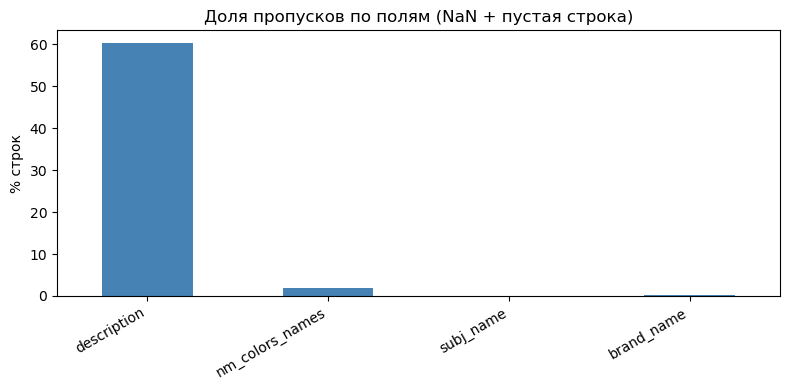


=== subj_root_name внутри отфильтрованного подмножества ===
subj_root_name
Одежда    43316
Обувь     13187
Name: count, dtype: int64

Всего уникальных subj_name: 104

Топ-15 самых частых subj_name:
subj_name
Платья       6998
Футболки     5465
Брюки        3427
Блузки       2342
Костюмы      2317
Туфли        2159
Кроссовки    1835
Джинсы       1746
Рубашки      1689
Юбки         1647
Ботинки      1502
Джемперы     1442
Куртки       1391
Шорты        1240
Босоножки    1205
Name: count, dtype: int64

Самые редкие subj_name (хвост):
subj_name
Шубы чебурашки           13
Дубленки                 12
Топсайдеры               11
Килты банные             10
Мантии                    9
Крестильные комплекты     8
Анораки                   7
Пончо                     6
Шорты пижамные            5
Топы пижамные             4
Крестильные рубашки       2
Косухи                    1
Дафлкоты                  1
Крестильные платья        1
Брюки пижамные            1
Name: count, dtype: int64


In [12]:
# Визуализация 1: доля пропусков по полям
fig, ax = plt.subplots(figsize=(8, 4))
missing_report["total_missing_pct"].plot(kind="bar", ax=ax, color="steelblue")
ax.set_title("Доля пропусков по полям (NaN + пустая строка)")
ax.set_ylabel("% строк")
ax.set_xlabel("")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

# --- Распределение по категориям ---
print("\n=== subj_root_name внутри отфильтрованного подмножества ===")
print(df_scope["subj_root_name"].value_counts())

subj_name_counts = df_scope["subj_name"].value_counts()
print(f"\nВсего уникальных subj_name: {len(subj_name_counts)}")
print("\nТоп-15 самых частых subj_name:")
print(subj_name_counts.head(15))
print("\nСамые редкие subj_name (хвост):")
print(subj_name_counts.tail(15))



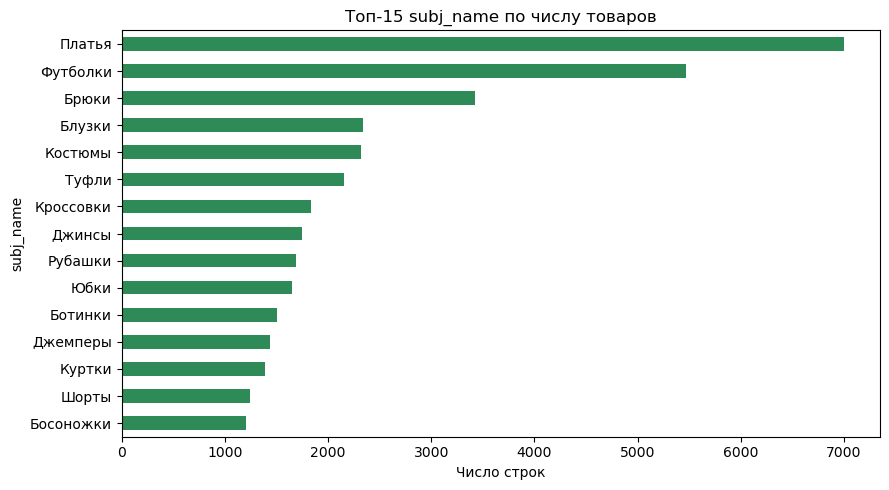


=== Статистика длины imt_name (слова) ===
count    56503.000000
mean         1.999363
std          1.958129
min          0.000000
25%          1.000000
50%          1.000000
75%          2.000000
max         19.000000
Name: imt_name_len_words, dtype: float64

=== Статистика длины description (слова, только непустые) ===
count    22428.000000
mean        64.800874
std         69.131150
min          1.000000
25%         23.000000
50%         42.000000
75%         84.000000
max        704.000000
Name: description_len_words, dtype: float64


In [13]:
# Визуализация 2: топ-15 категорий subj_name
fig, ax = plt.subplots(figsize=(9, 5))
subj_name_counts.head(15).plot(kind="barh", ax=ax, color="seagreen")
ax.invert_yaxis()
ax.set_title("Топ-15 subj_name по числу товаров")
ax.set_xlabel("Число строк")
plt.tight_layout()
plt.show()

# --- Длина текстовых полей ---
df_scope["imt_name_len_words"] = df_scope["imt_name"].fillna("").str.split().str.len()
df_scope["imt_name_len_chars"] = df_scope["imt_name"].fillna("").str.len()
df_scope["description_len_words"] = df_scope["description"].fillna("").str.split().str.len()
df_scope["description_len_chars"] = df_scope["description"].fillna("").str.len()

print("\n=== Статистика длины imt_name (слова) ===")
print(df_scope["imt_name_len_words"].describe())
print("\n=== Статистика длины description (слова, только непустые) ===")
print(df_scope.loc[df_scope["description_len_words"] > 0, "description_len_words"].describe())



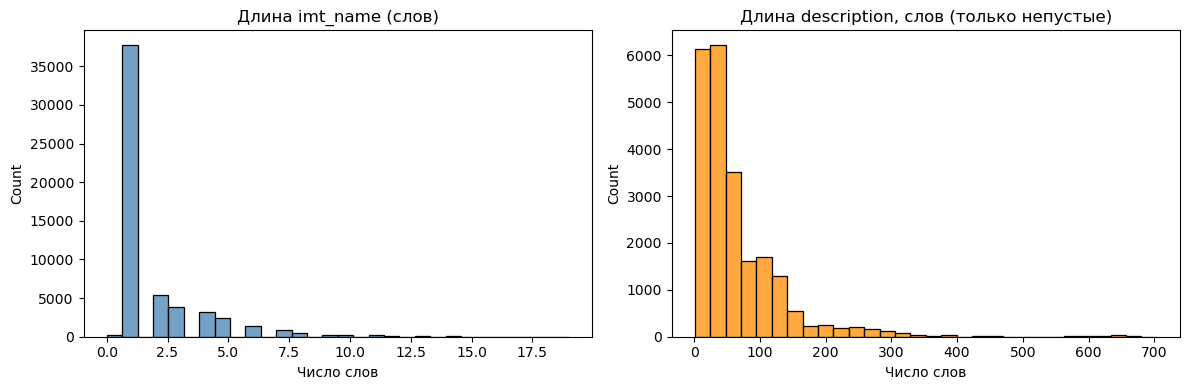


=== Топ-5 самых длинных description (в словах) ===


,imt_id,imt_name,description_len_words
132091,10119657,Туфли кожаные мужские туфли натуральная кожа к...,704
114342,10103313,,699
6237,10005381,Юбка джинсовая,679
129777,10117616,Юбка детская джинсовая мини для девочки летняя...,678
129778,10117616,Юбка детская джинсовая мини для девочки летняя...,678



Уникальных брендов: 3916
Доля строк, где цвет уже упомянут в imt_name: 2.3%


In [14]:
# Визуализация 3: гистограммы длины названия и описания
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df_scope["imt_name_len_words"], bins=30, ax=axes[0], color="steelblue")
axes[0].set_title("Длина imt_name (слов)")
axes[0].set_xlabel("Число слов")

desc_nonempty = df_scope.loc[df_scope["description_len_words"] > 0, "description_len_words"]
sns.histplot(desc_nonempty, bins=30, ax=axes[1], color="darkorange")
axes[1].set_title("Длина description, слов (только непустые)")
axes[1].set_xlabel("Число слов")
plt.tight_layout()
plt.show()

# Выбросы: экстремально длинные описания
print("\n=== Топ-5 самых длинных description (в словах) ===")
display(
    df_scope.nlargest(5, "description_len_words")[["imt_id", "imt_name", "description_len_words"]]
)

# --- Бренд и цвет ---
print(f"\nУникальных брендов: {df_scope['brand_name'].nunique()}")

color_in_name = df_scope.apply(
    lambda row: isinstance(row["nm_colors_names"], str)
    and isinstance(row["imt_name"], str)
    and row["nm_colors_names"].lower() in row["imt_name"].lower(),
    axis=1,
)
print(f"Доля строк, где цвет уже упомянут в imt_name: {color_in_name.mean() * 100:.1f}%")

In [15]:
sample_check = df_scope.sample(25, random_state=SEED)[
    ["imt_id", "imt_name", "subj_name", "description", "brand_name", "nm_colors_names"]
]
pd.set_option("display.max_colwidth", 150)
display(sample_check)



,imt_id,imt_name,subj_name,description,brand_name,nm_colors_names
85717,1007705,Сапоги,Сапоги,,Vitacci,черный
73576,10066007,Брюки,Брюки,,KOTON,черный
171326,1015934,Платье,Платья,,Colambetta,"синий, белый"
67663,10060803,Кардиган,Кардиганы,"Важная информация! При заказе изделия, обращайте особое внимание на его параметры, указанные в таблице соответствия. Удлиненный кардиган прямого с...",Velvet Season,бежевый
87795,10078984,Туфли,Туфли,,МЫШОНОК,черный
135770,10127551,Женские брюки,Брюки,,MODERNFECI,бледно-розовый
54495,10048604,Рубашка,Рубашки,,DeFacto,голубой
193603,10178775,Футболка,Футболки,,ТВОЕ,темно-серый
2606,1000231,Пальто,Пальто,,Kling,"черный, красный, оранжевый"
30453,10027497,Босоножки,Босоножки,,Buzoni,бежевый


In [16]:
print("Всего пар «запрос — товар» в train:", len(queries_train))
print("Уникальных query_id в train:", queries_train["query_id"].nunique())

items_per_query = queries_train.groupby("query_id").size()
print("\nЧисло оценённых товаров на один запрос:")
print(items_per_query.describe())

print("\n=== Распределение relevance ===")
relevance_counts = queries_train["relevance"].value_counts().sort_index()
print(relevance_counts)
print("\nДоли:")
print((relevance_counts / len(queries_train) * 100).round(1))



Всего пар «запрос — товар» в train: 11453
Уникальных query_id в train: 700

Число оценённых товаров на один запрос:
count    700.000000
mean      16.361429
std        5.424150
min        1.000000
25%       14.000000
50%       16.000000
75%       19.000000
max       31.000000
dtype: float64

=== Распределение relevance ===
relevance
1    9652
2    1101
3     700
Name: count, dtype: int64

Доли:
relevance
1    84.3
2     9.6
3     6.1
Name: count, dtype: float64


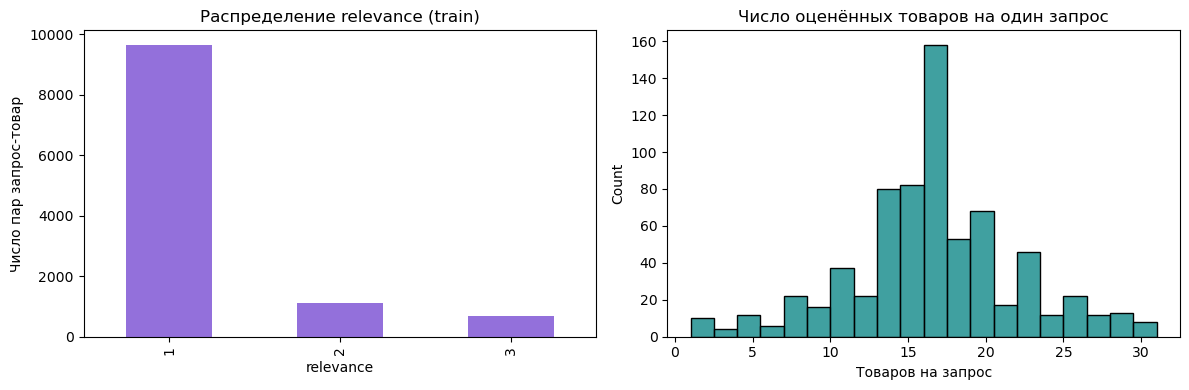

In [17]:
# Визуализация: распределение relevance
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

relevance_counts.plot(kind="bar", ax=axes[0], color="mediumpurple")
axes[0].set_title("Распределение relevance (train)")
axes[0].set_xlabel("relevance")
axes[0].set_ylabel("Число пар запрос-товар")

sns.histplot(items_per_query, bins=20, ax=axes[1], color="teal")
axes[1].set_title("Число оценённых товаров на один запрос")
axes[1].set_xlabel("Товаров на запрос")
plt.tight_layout()
plt.show()



In [18]:
# --- Природа запросов: примеры ---
print("\n=== Случайные примеры query_text ===")
print(queries_train["query_text"].drop_duplicates().sample(10, random_state=SEED).to_list())


=== Случайные примеры query_text ===
['топы cop copine', 'худи mego as', 'бриджи зуавы', 'кожаные мокасины', 'кожаные сабо с открытым мысом', 'классические джинсовые джинсы', 'шубы натуральные на пуговицах', 'тапочки asd', 'тапочки t taccardi', 'кигуруми londe']


## Выводы по EDA

**Отбор категорий.** Из 65 корневых категорий выбраны `Одежда` (43 316 строк) и `Обувь` (13 187 строк) — только по ним есть оценки релевантности. После фильтрации: 56 503 строки, 48 489 уникальных `imt_id`, 104 уникальных `subj_name`.

**Пропуски.** Только `description` — системная проблема: пропущено (NaN + пустая строка) 60.3% строк. `nm_colors_names` — 1.8% пропусков, `brand_name` — 0.13%, `subj_name` пропусков не имеет. Раз у 60% товаров нет описания, текст для эмбеддинга у них будет состоять только из названия и категории — это системное свойство каталога, а не редкое исключение.

**Категории.** Топ subj_name — «Платья» (6 998), «Футболки» (5 465), «Брюки» (3 427); хвост распределения — множество subj_name с 1 строкой («Дафлкоты», «Крестильные платья», «Брюки пижамные» и т.п.). Такие редкие категории — кандидаты на особые случаи при оценке: система физически не может показать высокое качество на товаре, у которого в каталоге почти нет аналогов.

**Длина текста.** `imt_name` короткие: медиана 1 слово, среднее ≈2 слова, максимум 19 слов — названия скорее опознавательные («Платье», «Кроссовки»), чем описательные. `description` (только непустые, 22 428 строк) — медиана 42 слова, среднее ≈65, максимум 704 слова (выбросы — вероятно, SEO-тексты или длинные таблицы размеров). Разброс большой (std ≈69), так что шаблон `product_text` должен учитывать возможность как пустого, так и очень длинного описания.

**Ручная проверка текста (25 карточек).** Явных HTML-тегов не встретилось. Заметны шаблонные вставки не по сути товара — например, предупреждения о размерах («Данная модель обуви … маломерит», «При заказе изделия обращайте внимание…») в начале `description`, что размывает смысловое ядро текста. Заметно совпадение `subj_name` с общим словом в `imt_name` (например, `imt_name = "Сапоги"`, `subj_name = "Сапоги"`) — в таких случаях название несёт мало уникальной информации.

**Бренд и цвет.** 3 916 уникальных брендов. Цвет упомянут в `imt_name` только у 2.3% строк — то есть дублирования между `imt_name` и `nm_colors_names` почти нет, оба поля несут разную информацию. Наставник указал не использовать бренд в тексте для эмбеддинга — эти данные подтверждают, что бренд действительно избыточен для текста, но может пригодиться как отдельный признак для фильтрации.

**Разметка (train).** 11 453 пары «запрос-товар», 700 уникальных запросов, в среднем ≈16 оценённых товаров на запрос (от 1 до 31) — это верхняя граница для Precision@K/Recall@K при интерпретации метрик.

**Распределение relevance.** Только положительные оценки: 1 — 84.3%, 2 — 9.6%, 3 — 6.1%. **Оценки 0 в разметке отсутствуют вовсе** — значит, весь `relevance = 0` в оценке качества будет появляться только за счёт товаров, не попавших в разметку конкретного запроса (по правилу методики «не в разметке → нерелевантно»). Это стоит явно зафиксировать: без этого правила метрики посчитать вообще нельзя, разметка сама по себе не содержит отрицательных примеров.

**Природа запросов.** Примеры (`топы cop copine`, `худи mego as`, `тапочки asd`, `тапочки t taccardi`) показывают, что часть синтетических запросов выглядит как категория + странный «хвост» (обрывок бренда/шума), а не как естественный пользовательский запрос. Это стоит учитывать при интерпретации ошибок семантического поиска — модель может законно не находить соответствие для шумных «хвостов», и такие случаи не всегда говорят о слабости самого подхода.

---

## Неделя 2 — базовый пайплайн и оценка качества

**Цель:** оперевшись на результаты EDA, создать работающий поиск и получить первые метрики качества.

Прежде чем реализовывать семантический поиск, основанный на эмбеддингах, нужно проверить, как справляется более простая модель, опирающаяся на TF-IDF. Простая модель нужна как baseline, без этой точки отсчёта результат невозможно интерпретировать.


### 1. Подготовка данных


Реализуйте решения недели 1:

1. Отфильтруйте выбранные категории.
2. Дедуплицируйте строки по `imt_id`. Сформулируйте правило, по которому будете определять, какую строку оставить. К примеру, можете оставить строку с самым информативным описанием. Ответ обоснуйте.
3. Отбросьте карточки, у которых пусты одновременно и `imt_name`, и `description`.
4. Напишите функцию очистки текста.
5. Соберите единый текст карточек в отдельной колонке `product_text`.

In [19]:
# Отбор подмножества (повторяем фильтр из EDA, на случай что ячейка выполняется отдельно) 
TARGET_ROOT_CATEGORIES = ["Одежда", "Обувь"]
df_scope = df_raw[df_raw["subj_root_name"].isin(TARGET_ROOT_CATEGORIES)].copy()
print(f"После фильтрации категорий: {len(df_scope)} строк, {df_scope['imt_id'].nunique()} уникальных imt_id")



После фильтрации категорий: 56503 строк, 48489 уникальных imt_id


In [20]:
# --- 2. Дедупликация по imt_id ---
# Правило: оставляем строку с самым длинным непустым description.
# Обоснование: более длинное описание обычно содержит больше полезной для
# семантики информации (материал, назначение, детали), чем короткое или
# пустое — это напрямую улучшает эмбеддинг карточки.
df_scope["_description_len"] = df_scope["description"].fillna("").str.len()

df_dedup = (
    df_scope.sort_values("_description_len", ascending=False)
    .drop_duplicates(subset="imt_id", keep="first")
    .drop(columns="_description_len")
    .reset_index(drop=True)
)

print(f"После дедупликации по imt_id: {len(df_dedup)} строк (было {len(df_scope)})")
print(f"Удалено дублей: {len(df_scope) - len(df_dedup)}")



После дедупликации по imt_id: 48489 строк (было 56503)
Удалено дублей: 8014


In [21]:
# --- 3. Отсев карточек без текста (пусты и imt_name, и description) ---
imt_name_empty = df_dedup["imt_name"].isna() | (df_dedup["imt_name"] == "")
description_empty = df_dedup["description"].isna() | (df_dedup["description"] == "")
both_empty = imt_name_empty & description_empty

print(f"\nКарточек с пустыми и imt_name, и description: {both_empty.sum()}")

df_clean = df_dedup[~both_empty].reset_index(drop=True)
print(f"После отсева: {len(df_clean)} строк (было {len(df_dedup)})")





Карточек с пустыми и imt_name, и description: 113
После отсева: 48376 строк (было 48489)


In [22]:
# --- 4. Функция очистки текста ---
# Шаблонные фразы не по сути товара, найденные при ручном просмотре карточек
# (недели 1): предупреждения о размерах, отсылки к таблицам соответствия.
BOILERPLATE_PATTERNS = [
    r"[^.!?]*маломерит[^.!?]*[.!?]?",
    r"[^.!?]*таблиц[а-я]* (размеров|соответствия)[^.!?]*[.!?]?",
    r"[^.!?]*обращайте (особое )?внимание[^.!?]*[.!?]?",
    r"важная информация!?",
]
BOILERPLATE_RE = re.compile("|".join(BOILERPLATE_PATTERNS), flags=re.IGNORECASE)

HTML_TAG_RE = re.compile(r"<[^>]+>")
MULTI_SPACE_RE = re.compile(r"\s+")


def clean_text(text) -> str:
    """Очищает текст карточки от HTML-тегов, шаблонных вставок и лишних пробелов."""
    if not isinstance(text, str) or not text.strip():
        return ""

    text = HTML_TAG_RE.sub(" ", text)
    text = BOILERPLATE_RE.sub(" ", text)
    text = MULTI_SPACE_RE.sub(" ", text).strip()
    return text


# Проверка функции на нескольких примерах
for sample in df_clean["description"].dropna().sample(5, random_state=SEED):
    cleaned = clean_text(sample)
    print("ДО:  ", sample[:120])
    print("ПОСЛЕ:", cleaned[:120])
    print()

df_clean["imt_name_clean"] = df_clean["imt_name"].apply(clean_text)
df_clean["description_clean"] = df_clean["description"].apply(clean_text)




ДО:   
ПОСЛЕ: 

ДО:   Детские шлепанцы HUSKY - это универсальная обувь, подходящая как для бассейна, так и для активного отдыха. Шлепанцы очен
ПОСЛЕ: Детские шлепанцы HUSKY - это универсальная обувь, подходящая как для бассейна, так и для активного отдыха. Шлепанцы очен

ДО:   
ПОСЛЕ: 

ДО:   
ПОСЛЕ: 

ДО:   На фотографии параметры модели: рост 160 см, размер 42/XS. Длина по внутреннему шву  26 см. Внешняя длина 51 см.
ПОСЛЕ: На фотографии параметры модели: рост 160 см, размер 42/XS. Длина по внутреннему шву 26 см. Внешняя длина 51 см.



In [23]:
# --- 5-6. Сборка product_text ---
def build_product_text(row) -> str:
    """
    Шаблон: imt_name + subj_name + description.
    Бренд и цвет намеренно не включаем (решение с QA-сессии: бренд не должен
    влиять на семантическую выдачу; цвет почти не дублирует imt_name — 2.3%).
    Явный разделитель " . " между полями, пустые поля пропускаются.
    """
    parts = [
        row["imt_name_clean"],
        row["subj_name"] if isinstance(row["subj_name"], str) else "",
        row["description_clean"],
    ]
    parts = [p.strip() for p in parts if isinstance(p, str) and p.strip()]
    return " . ".join(parts)


df_clean["product_text"] = df_clean.apply(build_product_text, axis=1)

print(f"\nИтоговый каталог: {len(df_clean)} строк")
print(f"Пустых product_text: {(df_clean['product_text'] == '').sum()}")

# Проверка вручную на 5-10 примерах
display(df_clean[["imt_id", "imt_name", "subj_name", "product_text"]].sample(8, random_state=SEED))


Итоговый каталог: 48376 строк
Пустых product_text: 0


,imt_id,imt_name,subj_name,product_text
47215,10067476,Юбка,Юбки,Юбка . Юбки
6467,10093130,Юниорские тапочки HUSKY,Шлепанцы,"Юниорские тапочки HUSKY . Шлепанцы . Детские шлепанцы HUSKY - это универсальная обувь, подходящая как для бассейна, так и для активного отдыха. Шл..."
43348,1009823,Футболка,Футболки,Футболка . Футболки
48236,10069674,Леггинсы,Леггинсы,Леггинсы . Леггинсы
15302,10048019,Шорты,Шорты,"Шорты . Шорты . На фотографии параметры модели: рост 160 см, размер 42/XS. Длина по внутреннему шву 26 см. Внешняя длина 51 см."
33752,10048077,Футболка,Футболки,Футболка . Футболки
46722,1007530,Платье,Платья,Платье . Платья
38335,1001867,Лонгслив-поло,Лонгсливы,Лонгслив-поло . Лонгсливы


**Подготовка данных — результат.**

- После фильтрации категорий (Одежда + Обувь): 56 503 строки, 48 489 уникальных `imt_id`.
- Дедупликация по `imt_id` (правило: оставляем строку с самым длинным `description`): удалено 8 014 дублей-артикулов, итог — 48 489 строк (одна на карточку).
- Отсев карточек без текста (пусты и `imt_name`, и `description`): удалено 113 строк.
- Итоговый рабочий каталог: **48 376 карточек**, пустых `product_text` — 0.
- Шаблон `product_text`: `imt_name + subj_name + description` (после очистки), разделитель `" . "`, пустые поля пропускаются. Бренд и цвет не включены (см. обоснование в EDA и решение с QA-сессии).

### Каталог для поиска и оценки

1. Посчитайте метрику при поиске по всему отфильтрованному каталогу. Например, вычислите NDCG@10 лексическим поиском на 100 запросах.
2. Выведите топ-10 для одного запроса и отметьте, какие товары есть в разметке, а каких нет. Выясните, в чём проблема.
3. Ограничьте каталог оценки пулом асессоров: возьмите из `wb_products_dedup.parquet` только список `imt_id` и оставьте в своём подготовленном каталоге пересечение с ним. Тексты и все признаки — ваши, из шага 1.
4. Пересчитайте метрику и сравните результаты.
5. Посмотрите на распределение `relevance` и число оценённых товаров на запрос. Проверьте, у всех ли запросов есть товары с `relevance` ≥ 2.

In [24]:
# --- Подготовка golden-сета из train ---
# Формат: query_id -> {"text": ..., "labels": {item_id: relevance, ...}}
golden_set = {}
for qid, group in queries_train.groupby("query_id"):
    golden_set[qid] = {
        "text": group["query_text"].iloc[0],
        "labels": dict(zip(group["item_id"], group["relevance"])),
    }

print(f"Всего запросов в golden-сете: {len(golden_set)}")


def ndcg_at_k(ranked_item_ids, labels: dict, k: int = 10) -> float:
    """NDCG@k по полной шкале relevance (0-3), gain = 2^rel - 1."""
    dcg = 0.0
    for i, item_id in enumerate(ranked_item_ids[:k]):
        rel = labels.get(item_id, 0)
        gain = (2 ** rel) - 1
        dcg += gain / np.log2(i + 2)  # позиции с 1, log2(1+1)=1

    ideal_rels = sorted(labels.values(), reverse=True)[:k]
    idcg = sum(((2 ** rel) - 1) / np.log2(i + 2) for i, rel in enumerate(ideal_rels))

    return dcg / idcg if idcg > 0 else 0.0


def build_tfidf_index(catalog_df: pd.DataFrame):
    vectorizer = TfidfVectorizer(ngram_range=(1, 2), max_features=50_000)
    matrix = vectorizer.fit_transform(catalog_df["product_text"])
    return vectorizer, matrix


def quick_lexical_search(query_text: str, catalog_df: pd.DataFrame, vectorizer, matrix, top_k: int = 10):
    query_vec = vectorizer.transform([query_text])
    scores = (matrix @ query_vec.T).toarray().ravel()
    top_idx = np.argsort(scores)[::-1][:top_k]
    return catalog_df["imt_id"].values[top_idx], scores[top_idx]




Всего запросов в golden-сете: 700


In [25]:
# Метрика при поиске по всему отфильтрованному каталогу 
vectorizer_full, matrix_full = build_tfidf_index(df_clean)

sample_query_ids = np.random.RandomState(SEED).choice(
    list(golden_set.keys()), size=100, replace=False
)

ndcg_scores_full = []
for qid in sample_query_ids:
    q = golden_set[qid]
    ranked_ids, _ = quick_lexical_search(q["text"], df_clean, vectorizer_full, matrix_full, top_k=10)
    ndcg_scores_full.append(ndcg_at_k(ranked_ids, q["labels"], k=10))

print(f"\nNDCG@10 (лексический поиск, весь каталог {len(df_clean)} товаров, 100 запросов): "
      f"{np.mean(ndcg_scores_full):.4f}")





NDCG@10 (лексический поиск, весь каталог 48376 товаров, 100 запросов): 0.0575


In [26]:
# Топ-10 для одного запроса — что размечено, а что нет 
example_qid = sample_query_ids[0]
example_q = golden_set[example_qid]
ranked_ids, ranked_scores = quick_lexical_search(
    example_q["text"], df_clean, vectorizer_full, matrix_full, top_k=10
)

print(f"\n=== Пример: запрос «{example_q['text']}» (query_id={example_qid}) ===")
for item_id, score in zip(ranked_ids, ranked_scores):
    in_labels = item_id in example_q["labels"]
    rel = example_q["labels"].get(item_id, "—")
    name = df_clean.loc[df_clean["imt_id"] == item_id, "imt_name"].values
    name = name[0] if len(name) else "?"
    print(f"  imt_id={item_id:>10} score={score:.3f} "
          f"{'В РАЗМЕТКЕ (rel=' + str(rel) + ')' if in_labels else 'нет в разметке':<25} {name}")

n_in_labels = sum(1 for i in ranked_ids if i in example_q["labels"])
print(f"\nИз топ-10: {n_in_labels} товаров есть в разметке этого запроса, "
      f"{10 - n_in_labels} — нет.")
print("Диагноз: поиск идёт по всему каталогу (48k+ карточек), а асессоры оценивали")
print("только пул из wb_products_dedup.parquet (несколько тысяч карточек). Система")
print("может найти вполне разумный товар, которого асессоры просто не видели —")
print("и такой товар засчитывается нерелевантным, хотя мог бы быть релевантным.")





=== Пример: запрос «топы cop copine» (query_id=SYN_000210) ===
  imt_id=  10097046 score=0.865 нет в разметке            Платье
  imt_id=  10048067 score=0.848 нет в разметке            Футболка
  imt_id=  10016978 score=0.767 нет в разметке            Топы
  imt_id=  10133186 score=0.767 нет в разметке            Топы
  imt_id=  10133188 score=0.767 нет в разметке            Топы
  imt_id=  10133187 score=0.767 нет в разметке            Топы
  imt_id=  10016979 score=0.767 нет в разметке            Топы
  imt_id=  10067786 score=0.767 нет в разметке            Топы
  imt_id=  10016976 score=0.767 нет в разметке            Топы
  imt_id=  10124446 score=0.767 нет в разметке            Топы

Из топ-10: 0 товаров есть в разметке этого запроса, 10 — нет.
Диагноз: поиск идёт по всему каталогу (48k+ карточек), а асессоры оценивали
только пул из wb_products_dedup.parquet (несколько тысяч карточек). Система
может найти вполне разумный товар, которого асессоры просто не видели —
и такой товар

In [27]:
# Ограничение каталога пулом асессоров 
df_dedup_pool = pd.read_parquet(ASSESSED_POOL_PATH, engine="fastparquet")
dedup_ids = set(df_dedup_pool["imt_id"])

print(f"\nКарточек в пуле асессоров (wb_products_dedup): {len(dedup_ids)}")

df_catalog_eval = df_clean[df_clean["imt_id"].isin(dedup_ids)].reset_index(drop=True)
print(f"Пересечение с нашим подготовленным каталогом: {len(df_catalog_eval)} карточек "
      f"(из {len(df_clean)})")





Карточек в пуле асессоров (wb_products_dedup): 4256
Пересечение с нашим подготовленным каталогом: 4256 карточек (из 48376)


In [28]:
# Пересчёт метрики на ограниченном каталоге ===
vectorizer_eval, matrix_eval = build_tfidf_index(df_catalog_eval)

ndcg_scores_eval = []
for qid in sample_query_ids:
    q = golden_set[qid]
    ranked_ids, _ = quick_lexical_search(q["text"], df_catalog_eval, vectorizer_eval, matrix_eval, top_k=10)
    ndcg_scores_eval.append(ndcg_at_k(ranked_ids, q["labels"], k=10))

print(f"\nNDCG@10 (лексический поиск, каталог оценки {len(df_catalog_eval)} товаров, "
      f"те же 100 запросов): {np.mean(ndcg_scores_eval):.4f}")
print(f"Было (весь каталог): {np.mean(ndcg_scores_full):.4f}")
print(f"Разница: {np.mean(ndcg_scores_eval) - np.mean(ndcg_scores_full):+.4f}")





NDCG@10 (лексический поиск, каталог оценки 4256 товаров, те же 100 запросов): 0.4442
Было (весь каталог): 0.0575
Разница: +0.3868


In [29]:
# Распределение relevance и покрытие релевантными товарами 
all_relevances = [rel for q in golden_set.values() for rel in q["labels"].values()]
print("\n=== Распределение relevance по всем запросам golden-сета ===")
print(pd.Series(all_relevances).value_counts().sort_index())

queries_without_high_rel = [
    qid for qid, q in golden_set.items()
    if not any(rel >= 2 for rel in q["labels"].values())
]
print(f"\nЗапросов без товаров с relevance >= 2: {len(queries_without_high_rel)} "
      f"из {len(golden_set)} ({len(queries_without_high_rel) / len(golden_set) * 100:.1f}%)")


=== Распределение relevance по всем запросам golden-сета ===
1    9652
2    1101
3     700
Name: count, dtype: int64

Запросов без товаров с relevance >= 2: 0 из 700 (0.0%)


**Каталог для поиска и оценки — результат.**

- **NDCG@10 на всём подготовленном каталоге (48 376 товаров):** 

0.0575 — крайне низкое значение.

- **Диагностика на примере запроса «топы cop copine».** 

Топ-10 лексического поиска — все товары категории «Топы»/близкие, то есть выдача содержательно адекватна, но **0 из 10** есть в разметке этого запроса. Проблема не в качестве поиска, а в масштабе каталога: асессоры размечали не весь каталог, а фиксированный пул (`wb_products_dedup.parquet`), и система стабильно находит разумные, но неразмеченные товары — они засчитываются нерелевантными, хотя могли бы быть в топе у асессоров.

- **Пул асессоров:** 4 256 карточек, все они полностью входят в наш подготовленный каталог (пересечение = 4 256 из 4 256) — потерь на этапе фильтрации/дедупликации нет.

- **NDCG@10 на каталоге оценки (4 256 товаров):** 0.4442 — прирост **+0.3868** относительно поиска по всему каталогу. Разница подтверждает: оценка должна идти строго по каталогу асессоров (`wb_products_dedup`), а не по всему подготовленному каталогу — иначе метрики искусственно занижены и не отражают реальное качество системы.

- **Распределение relevance** по всей разметке (700 запросов): 1 — 9 652 (84.3%), 2 — 1 101 (9.6%), 3 — 700 (6.1%) — совпадает с тем, что видели на train при EDA.

- **Покрытие сильно релевантными товарами:** у **всех 700 запросов (100%)** есть хотя бы один товар с `relevance ≥ 2`. Это хорошая новость для дальнейшей оценки — ни один запрос не придётся исключать из-за отсутствия «правильного» ответа.

**Вывод:** дальше метрики считаем **только по ограниченному каталогу оценки** (`df_catalog_eval`, 4 256 карточек), а не по всему подготовленному каталогу.

### 2. Модели поиска

Реализуйте два поисковых движка с одинаковым интерфейсом. Это позволит прогнать оба через одну функцию оценки:

In [30]:
def search_lexical(query: str, top_k: int = 10) -> pd.DataFrame:
    """Возвращает top_k товаров с колонками imt_id, imt_name, subj_name, score.
    Поиск идёт по каталогу оценки (df_catalog_eval), TF-IDF + косинусная близость.
    """
    query_clean = clean_text(query)
    query_vec = vectorizer_eval.transform([query_clean])
    scores = (matrix_eval @ query_vec.T).toarray().ravel()

    top_idx = np.argsort(scores)[::-1][:top_k]

    result = df_catalog_eval.iloc[top_idx][["imt_id", "imt_name", "subj_name"]].copy()
    result["score"] = scores[top_idx]
    return result.reset_index(drop=True)




Реализуйте лексический baseline на TF-IDF:

In [31]:
# Ручная проверка на нескольких запросах
for q in ["удобные кроссовки для бега", "черное платье на выпускной", "теплая куртка зимняя"]:
    print(f"\n=== Запрос: «{q}» ===")
    display(search_lexical(q, top_k=5))


=== Запрос: «удобные кроссовки для бега» ===


,imt_id,imt_name,subj_name,score
0,10152000,Кроссовки 500,Кроссовки,0.260909
1,10076338,Кроссовки Abyss,Кроссовки,0.260909
2,10007080,Кроссовки FALCON W VAPPNK/SIGORG/LEGBLU,Кроссовки,0.260909
3,10152002,Кроссовки 527,Кроссовки,0.260909
4,10152011,Кроссовки Roav,Кроссовки,0.260909



=== Запрос: «черное платье на выпускной» ===


,imt_id,imt_name,subj_name,score
0,10039083,Платье,Платья,0.255838
1,10003710,"Сарафан / Женское офисное короткое платье, большие размеры, для дома, повседневное, трикотажное",Сарафаны,0.208113
2,10003711,"Женское вечернее офисное короткое платье, большие размеры, праздничное, повседневное, трикотажное",Платья,0.205571
3,10003713,"Женское вечернее офисное короткое платье, большие размеры, праздничное, повседневное, трикотажное",Платья,0.204500
4,10149677,Сарафан,Сарафаны,0.201353



=== Запрос: «теплая куртка зимняя» ===


,imt_id,imt_name,subj_name,score
0,10000525,Зимняя флисовая куртка,Куртки,0.469533
1,10009937,Куртка байкерская - MARCMOTO,Куртки,0.333154
2,10034209,Куртка,Кофты,0.291135
3,10121056,Куртка,Ветровки,0.280476
4,10056767,Куртка,Куртки,0.278540


Реализуйте семантический поиск:

In [32]:
# Модель: мультиязычная, с поддержкой русского, компактная для MVP.
# paraphrase-multilingual-MiniLM-L12-v2: 118M параметров, лимит 128 токенов,
EMBEDDING_MODEL_NAME = "paraphrase-multilingual-MiniLM-L12-v2"
embedding_model = SentenceTransformer(EMBEDDING_MODEL_NAME)

print("Максимальная длина входа модели (токенов):", embedding_model.max_seq_length)

# Считаем эмбеддинги каталога оценки батчами и сохраняем на диск 
CATALOG_EMBEDDINGS_PATH = "catalog_embeddings.npy"

if os.path.exists(CATALOG_EMBEDDINGS_PATH):
    catalog_embeddings = np.load(CATALOG_EMBEDDINGS_PATH)
    print(f"Эмбеддинги загружены с диска: {catalog_embeddings.shape}")
else:
    catalog_embeddings = embedding_model.encode(
        df_catalog_eval["product_text"].tolist(),
        batch_size=64,
        show_progress_bar=True,
        normalize_embeddings=True,  
    )
    np.save(CATALOG_EMBEDDINGS_PATH, catalog_embeddings)
    print(f"Эмбеддинги посчитаны и сохранены: {catalog_embeddings.shape}")


def search_semantic(query: str, top_k: int = 10) -> pd.DataFrame:
    """Возвращает top_k товаров с колонками imt_id, imt_name, subj_name, score.
    Поиск по каталогу оценки (df_catalog_eval), эмбеддинги той же модели.
    """
    query_embedding = embedding_model.encode([query], normalize_embeddings=True)
    scores = catalog_embeddings @ query_embedding[0]

    top_idx = np.argsort(scores)[::-1][:top_k]

    result = df_catalog_eval.iloc[top_idx][["imt_id", "imt_name", "subj_name"]].copy()
    result["score"] = scores[top_idx]
    return result.reset_index(drop=True)


# Ручная проверка на тех же запросах
for q in ["удобные кроссовки для бега", "черное платье на выпускной", "теплая куртка зимняя"]:
    print(f"\n=== Запрос: «{q}» ===")
    display(search_semantic(q, top_k=5))

Максимальная длина входа модели (токенов): 128
Эмбеддинги загружены с диска: (4256, 384)

=== Запрос: «удобные кроссовки для бега» ===


,imt_id,imt_name,subj_name,score
0,10109654,Кеды кожаные туфли повседневные 201707-4-1101,Полуботинки,0.819764
1,10109653,Кеды кожаные классические 201707-3-1301,Полуботинки,0.817878
2,10109648,Полуботинки кожаные туфли классические 201702-4-1101,Полуботинки,0.810388
3,10109662,Кроссовки кожаные повседневные 201725-1-1101,Полуботинки,0.810095
4,10036445,Кроссовки,Кроссовки,0.807022



=== Запрос: «черное платье на выпускной» ===


,imt_id,imt_name,subj_name,score
0,10032022,Платье с расклешенной юбкой,Платья,0.714077
1,10057865,Нарядное платье,Платья,0.682021
2,10174067,Бархатное платье-футляр,Платья,0.677402
3,10178235,Атласное платье миди,Платья,0.670942
4,10166139,"Короткое женское платье/на свадьбу, мероприятие, корпоратив, новый год 2022",Платья,0.664155



=== Запрос: «теплая куртка зимняя» ===


,imt_id,imt_name,subj_name,score
0,10000525,Зимняя флисовая куртка,Куртки,0.922821
1,10067910,Стеганое пальто,Пальто,0.838205
2,10163981,Кожанная куртка,Куртки,0.827458
3,10063797,Костюм зимний для девочки/Детский утеплённые костюм/Детский мембранный костюм,Костюмы,0.821923
4,10163982,Кожанное полупальто с капюшоном,Полупальто,0.818853


Прогоняем 3–5 запросов вручную и сравниваем выдачу обоих подходов. Это самый простой способ поймать грубые ошибки до подсчёта метрик.

In [33]:
random_query_ids = np.random.RandomState(SEED).choice(list(golden_set.keys()), size=3, replace=False)

for qid in random_query_ids:
    query_text = golden_set[qid]["text"]
    print(f"\n{'=' * 60}")
    print(f"Запрос: «{query_text}» (query_id={qid})")
    print("--- Лексический поиск ---")
    display(search_lexical(query_text, top_k=5))
    print("--- Семантический поиск ---")
    display(search_semantic(query_text, top_k=5))


Запрос: «топы cop copine» (query_id=SYN_000210)
--- Лексический поиск ---


,imt_id,imt_name,subj_name,score
0,10016977,Топы,Топы,0.771057
1,10150664,Топ - CINTIA,Топы,0.738804
2,10047446,Топ - TROPICO,Топы,0.738804
3,10095356,"Топ ""Juliet""",Топы,0.738804
4,101146,Топ,Топы,0.542130


--- Семантический поиск ---


,imt_id,imt_name,subj_name,score
0,100513,Пуловер,Пуловеры,0.595634
1,100221,Пуловер-поло,Пуловеры,0.587025
2,1012098,Джемпер,Кофты,0.573775
3,10096152,Блейзер,Пиджаки,0.561428
4,101218,Кофта,Кофты,0.556324



Запрос: «худи mego as» (query_id=SYN_000714)
--- Лексический поиск ---


...

,imt_id,imt_name,subj_name,score
0,10163985,Пальто кашемировое,Пальто,0.694544
1,10141414,Рубашка,Блузки,0.694290
2,10128768,Блузка,Рубашки,0.692511
3,10029843,Босоножки,Босоножки,0.680067
4,10048139,Худи оверсайз,Худи,0.678367



Запрос: «бриджи зуавы» (query_id=SYN_000561)
--- Лексический поиск ---


,imt_id,imt_name,subj_name,score
0,1003861,Бриджи,Бриджи,0.856820
1,10124357,Бриджи Тропики,Бриджи,0.692044
2,10000043,Бриджи/большие размеры/стрейч/ажур,Бриджи,0.596080
3,10005760,Бриджи женские/большого размера/Облегающие брюки/Капри,Бриджи,0.469338
4,10165872,Бриджи женские трикотажные большие размеры/спортивные/черные,Бриджи,0.431855


--- Семантический поиск ---


,imt_id,imt_name,subj_name,score
0,10079392,Байкал,Куртки,0.774090
1,10142636,Худи Raava,Худи,0.760837
2,10165930,Платье Айна,Платья,0.749972
3,10157344,"Платье ""Одилия""",Платья,0.740137
4,10084509,Сабо,Босоножки,0.738260


**Сравнение выдачи — наблюдения.**

- **«теплая куртка зимняя»**: оба подхода справились одинаково хорошо, топ-1 совпал («Зимняя флисовая куртка»). Семантика в целом чуть увереннее (score 0.92 vs 0.47) и предлагает более разнообразные, но уместные альтернативы (пальто, кожаная куртка, зимний костюм).
- **«черное платье на выпускной»**: здесь семантика явно сильнее. Лексика цепляется за буквальное слово «платье» и возвращает generic варианты («Платье», «Сарафан»), а семантика понимает повод и стиль — «Нарядное платье», «Бархатное платье-футляр», «Атласное платье миди». Классический пример, где смысл запроса важнее точных слов.
- **«худи mego as»**: обратная картина. Лексика находит точные совпадения по слову «худи» (score 1.0). Семантика полностью промахивается — в топ-5 нет ни одного худи, только «Пальто», «Рубашка», «Босоножки». Похоже, редкие/шумные латинские токены («mego», «as» — обрывок бренда) искажают эмбеддинг запроса.
- **«бриджи зуавы»**: тот же провал семантики в более выраженной форме. Лексика точно находит «Бриджи» (score 0.86), а семантика выдаёт полностью нерелевантный набор (куртка, худи, платья, сабо) — редкое слово «зуавы» модель, судя по всему, не может интерпретировать.

**Предварительный вывод:** семантический поиск сильнее там, где важно понять смысл/повод/стиль запроса, но заметно слабее на редких терминах и запросах с шумными/иноязычными вставками (обрывки брендов) — там выигрывает точное лексическое совпадение. Это прямой аргумент в пользу гибридного подхода (эксперимент недели 3).

### 3. Оценка качества решений

Реализуйте метрики Precision@K, Recall@K, MRR, NDCG@K, HitRate@K.

Три ключевые особенности, которые надо учесть при расчёте:

1. Порог бинаризации. Precision@K, Recall@K, MRR, HitRate@K бинарны, а шкала `relevance` — от `0` до `3`. С какой оценки товар считается релевантным? Вынесите порог в параметр, а не константу внутри функции.
2. NDCG считайте по полной шкале 0–3 (`gain = 2^rel - 1`), а не по бинаризованной, иначе теряется смысл градуированной разметки.
3. Неразмеченные товары в выдаче трактуйте как нерелевантные (`relevance_map.get(item_id, 0)`).

Выводы запишите в Markdown-ячейке и рабочем файле Markdown.

In [34]:
RELEVANCE_THRESHOLD = 2
# Обоснование: relevance=1 — товар лишь частично подходит (84.3% всей разметки),
# relevance=2 и 3 — товар явно соответствует запросу. Порог 2 отделяет
# "действительно релевантно" от "слабое совпадение", и по данным EDA у всех
# 700 запросов есть хотя бы один товар с relevance >= 2 — порог применим ко всем.


def precision_at_k(ranked_item_ids, labels: dict, k: int, threshold: int) -> float:
    top_k = ranked_item_ids[:k]
    relevant_count = sum(1 for i in top_k if labels.get(i, 0) >= threshold)
    return relevant_count / k


def recall_at_k(ranked_item_ids, labels: dict, k: int, threshold: int) -> float:
    total_relevant = sum(1 for rel in labels.values() if rel >= threshold)
    if total_relevant == 0:
        return 0.0
    top_k = ranked_item_ids[:k]
    found_relevant = sum(1 for i in top_k if labels.get(i, 0) >= threshold)
    return found_relevant / total_relevant


def hit_rate_at_k(ranked_item_ids, labels: dict, k: int, threshold: int) -> float:
    top_k = ranked_item_ids[:k]
    return 1.0 if any(labels.get(i, 0) >= threshold for i in top_k) else 0.0


def mrr(ranked_item_ids, labels: dict, threshold: int) -> float:
    for i, item_id in enumerate(ranked_item_ids):
        if labels.get(item_id, 0) >= threshold:
            return 1.0 / (i + 1)
    return 0.0


# ndcg_at_k уже реализован выше (раздел "Каталог для поиска и оценки"),
# использует полную шкалу relevance 0-3, порог бинаризации к нему не применяется.


def evaluate_search_function(search_fn, golden_set: dict, catalog_df: pd.DataFrame,
                              k_values=(1, 3, 5, 10), threshold: int = RELEVANCE_THRESHOLD):
    """Прогоняет search_fn по всем запросам golden_set и считает метрики для каждого k."""
    results = {k: {"precision": [], "recall": [], "hitrate": [], "ndcg": []} for k in k_values}
    mrr_scores = []

    for qid, q in golden_set.items():
        ranked_df = search_fn(q["text"], top_k=max(k_values))
        ranked_ids = ranked_df["imt_id"].tolist()

        mrr_scores.append(mrr(ranked_ids, q["labels"], threshold))

        for k in k_values:
            results[k]["precision"].append(precision_at_k(ranked_ids, q["labels"], k, threshold))
            results[k]["recall"].append(recall_at_k(ranked_ids, q["labels"], k, threshold))
            results[k]["hitrate"].append(hit_rate_at_k(ranked_ids, q["labels"], k, threshold))
            results[k]["ndcg"].append(ndcg_at_k(ranked_ids, q["labels"], k))

    summary_rows = []
    for k in k_values:
        summary_rows.append({
            "k": k,
            "Precision@k": np.mean(results[k]["precision"]),
            "Recall@k": np.mean(results[k]["recall"]),
            "HitRate@k": np.mean(results[k]["hitrate"]),
            "NDCG@k": np.mean(results[k]["ndcg"]),
        })

    summary_df = pd.DataFrame(summary_rows)
    summary_df["MRR"] = np.mean(mrr_scores)  # не зависит от k, добавлено для удобства сравнения
    return summary_df


print("Считаем метрики для лексического поиска (может занять минуту, 700 запросов)...")
metrics_lexical = evaluate_search_function(search_lexical, golden_set, df_catalog_eval)
metrics_lexical.insert(0, "method", "lexical")

print("Считаем метрики для семантического поиска...")
metrics_semantic = evaluate_search_function(search_semantic, golden_set, df_catalog_eval)
metrics_semantic.insert(0, "method", "semantic")

metrics_summary = pd.concat([metrics_lexical, metrics_semantic], ignore_index=True)

print(f"\n=== Сводная таблица метрик (порог бинаризации = {RELEVANCE_THRESHOLD}, "
      f"каталог оценки = {len(df_catalog_eval)} товаров, все 700 запросов) ===")
display(metrics_summary)

metrics_summary.to_csv("baseline_metrics.csv", index=False)
print("\nТаблица сохранена в baseline_metrics.csv")


Считаем метрики для лексического поиска (может занять минуту, 700 запросов)...
Считаем метрики для семантического поиска...

=== Сводная таблица метрик (порог бинаризации = 2, каталог оценки = 4256 товаров, все 700 запросов) ===


,method,k,Precision@k,Recall@k,HitRate@k,NDCG@k,MRR
0,lexical,1,0.068571,0.042055,0.068571,0.176939,0.146235
1,lexical,3,0.065238,0.092936,0.162857,0.278905,0.146235
2,lexical,5,0.066857,0.149707,0.234286,0.338600,0.146235
3,lexical,10,0.071286,0.286231,0.410000,0.430254,0.146235
4,semantic,1,0.062857,0.028409,0.062857,0.084490,0.111201
5,semantic,3,0.054286,0.063349,0.124286,0.119854,0.111201
6,semantic,5,0.046286,0.081681,0.165714,0.133056,0.111201
7,semantic,10,0.042714,0.138160,0.258571,0.151749,0.111201



Таблица сохранена в baseline_metrics.csv


**Метрики базовых решений — результат.**

Порог бинаризации `RELEVANCE_THRESHOLD = 2`, каталог оценки — 4 256 товаров (`df_catalog_eval`), все 700 запросов.

| method | k | Precision@k | Recall@k | HitRate@k | NDCG@k | MRR |
|---|---|---|---|---|---|---|
| lexical | 1 | 0.0686 | 0.0421 | 0.0686 | 0.1769 | 0.1462 |
| lexical | 10 | 0.0713 | 0.2862 | 0.4100 | 0.4303 | 0.1462 |
| semantic | 1 | 0.0629 | 0.0284 | 0.0629 | 0.0845 | 0.1112 |
| semantic | 10 | 0.0427 | 0.1382 | 0.2586 | 0.1517 | 0.1112 |

**Главный вывод: лексический baseline на TF-IDF обходит семантический поиск по абсолютно всем метрикам и на всех K.** NDCG@10: 0.430 (лексика) против 0.152 (семантика) — почти трёхкратный разрыв. HitRate@10: 0.41 против 0.26.

**Почему так вышло.** Это согласуется с ручным сравнением выдачи (шаг 3): выбранная модель — общая мультиязычная `paraphrase-multilingual-MiniLM-L12-v2`, не дообученная на доменной лексике каталога. Она хорошо улавливает смысл на «естественных» запросах («черное платье на выпускной»), но заметно проседает там, где: (а) запрос состоит из точного названия категории плюс шумных латинских вставок (обрывки брендов вроде «mego», «cop copine») — эмбеддинг искажается шумом; (б) запрос содержит редкий/специфичный термин («зуавы»), которого модель, по всей видимости, плохо «понимает». А поскольку доля таких «зашумлённых» синтетических запросов в разметке существенная, это систематически бьёт по семантике на всём датасете, а не только в отдельных примерах.

**Устойчивость по K.** У обоих подходов NDCG и Recall растут с ростом K (ожидаемо — больше шансов зацепить релевантный товар), а Precision почти не меняется (у лексики держится ~0.065–0.071) — значит, качество ранжирования первых позиций не выигрывает от увеличения выдачи, а плюс в Recall/NDCG идёт просто за счёт большего охвата.

**Про низкий Precision@10.** В среднем на запрос приходится ~2.6 товара с `relevance ≥ 2` (1 801 таких пар на 700 запросов) — то есть даже идеальная система не может дать Precision@10 выше ≈0.26. Наблюдаемые 0.071/0.043 — низкие даже с поправкой на этот предел, но сама по себе низкая абсолютная величина Precision@10 — не показатель катастрофы, важнее относительное сравнение подходов и NDCG/Recall.

**MRR** тоже выше у лексики (0.146 против 0.111) — лексический поиск в среднем быстрее выводит первый релевантный товар.

**Предварительный вывод для бизнеса (черновой, до экспериментов недели 3):** в текущей конфигурации внедрять именно эту семантическую модель как замену лексическому поиску не стоит — она работает хуже baseline. Прежде чем делать выводы о пользе векторного поиска в принципе, нужно попробовать более подходящую модель эмбеддингов и/или дообучение (неделя 3), а также гибридный подход, который бы использовал сильные стороны обоих методов.

---

## Неделя 3 — эксперименты, дообучение и MLflow

**Цель:** проверить гипотезы о том, как можно улучшить систему поиска, зафиксировать эксперименты, дать рекомендации бизнесу.

**Главное правило:** «один эксперимент — одна гипотеза — одно изменение». Если поменять сразу модель, шаблон текста и параметры векторизации, прирост будет невозможно объяснить и повторить.

### 1. Эксперименты по улучшению

Проведите минимум три эксперимента. Оформляйте каждый по схеме:

- **Гипотеза** — ваше предположение и его обоснование. Причины «хочу попробовать другую модель» недостаточно, нужны объяснения такого типа: «Модель с большим окном улучшит поиск товаров с длинными описаниями, потому что в EDA я видел, что X% описаний обрезаются по лимиту токенов».
- **Что меняется** — ровно один компонент относительно baseline.
- **Результат** — метрики на тех же данных, с тем же порогом и теми же K.
- **Вывод** — принимаем или отклоняем гипотезу. Что это говорит о данных?

Придумывайте гипотезы, опираясь на ошибки, которые обнаружили на неделе 2. Если выбранная модель путает смежные категории, попробуйте проверить, решит ли проблему добавление данных из `subj_name` в общий текст карточки. Другой пример: если лексический поиск обходит семантический на точных названиях, а семантический выигрывает у лексического, когда дело доходит до неточных формулировок, — это повод попробовать реализовать гибридный поиск.

Направления для разработки гипотез:

- изменить шаблон `product_text`;
- попробовать другую модель эмбеддингов;
- дообучить модели;
- реализовать гибридный поиск с помощью взвешенной суммы скоров или реранкинга семантикой поверх лексического отбора;
- ввести лемматизацию и стоп-слова для TF-IDF;
- изменить параметры векторизации.

### Гипотеза 1

Модель `paraphrase-multilingual-MiniLM-L12-v2` обучена на задаче paraphrase similarity
(сходство перефразировок), а не на задаче query-to-item retrieval — это разные цели:
близость "запрос ~ товар" концептуально отличается от близости "текст A ~ текст B,
означающих одно и то же". Модели семейства **E5** (`intfloat/multilingual-e5-base`)
специально обучены контрастивным способом именно на парах "запрос-документ" с явными
префиксами `query:`/`passage:`, поэтому должны точнее разделять релевантные и
нерелевантные товары для конкретного запроса. Ожидаем прирост NDCG@10 относительно
семантического baseline (0.152), возможно — приближение к лексическому baseline (0.430)
или превышение его.

### Что меняем

Только модель эмбеддингов (было `paraphrase-multilingual-MiniLM-L12-v2`,
стало `intfloat/multilingual-e5-base`) и добавление обязательных для E5 префиксов
`"query: "` / `"passage: "`. Всё остальное — тот же `product_text`, тот же каталог
оценки, тот же способ подсчёта метрик.

In [35]:

EXP1_MODEL_NAME = "intfloat/multilingual-e5-base"
EXP1_EMBEDDINGS_PATH = "catalog_embeddings_e5.npy"

exp1_model = SentenceTransformer(EXP1_MODEL_NAME)
print("Максимальная длина входа модели (токенов):", exp1_model.max_seq_length)

# E5 требует префиксы: "passage: " для документов, "query: " для запросов
if os.path.exists(EXP1_EMBEDDINGS_PATH):
    exp1_catalog_embeddings = np.load(EXP1_EMBEDDINGS_PATH)
    print(f"Эмбеддинги загружены с диска: {exp1_catalog_embeddings.shape}")
else:
    passages = ["passage: " + t for t in df_catalog_eval["product_text"].tolist()]
    exp1_catalog_embeddings = exp1_model.encode(
        passages,
        batch_size=64,
        show_progress_bar=True,
        normalize_embeddings=True,
    )
    np.save(EXP1_EMBEDDINGS_PATH, exp1_catalog_embeddings)
    print(f"Эмбеддинги посчитаны и сохранены: {exp1_catalog_embeddings.shape}")



...

Максимальная длина входа модели (токенов): 512
Эмбеддинги загружены с диска: (4256, 768)


Ellipsis

In [36]:
def search_semantic_e5(query: str, top_k: int = 10) -> pd.DataFrame:
    """search_semantic на модели intfloat/multilingual-e5-base (эксперимент 1)."""
    query_embedding = exp1_model.encode(["query: " + query], normalize_embeddings=True)
    scores = exp1_catalog_embeddings @ query_embedding[0]

    top_idx = np.argsort(scores)[::-1][:top_k]

    result = df_catalog_eval.iloc[top_idx][["imt_id", "imt_name", "subj_name"]].copy()
    result["score"] = scores[top_idx]
    return result.reset_index(drop=True)


# Ручная проверка на тех же "проблемных" запросах из недели 2
for q in ["худи mego as", "бриджи зуавы", "черное платье на выпускной"]:
    print(f"\n=== Запрос: «{q}» ===")
    display(search_semantic_e5(q, top_k=5))


# --- Результат: метрики на golden-сете (700 запросов) ---
print("\nСчитаем метрики для эксперимента 1 (e5-base)...")
metrics_exp1 = evaluate_search_function(search_semantic_e5, golden_set, df_catalog_eval)
metrics_exp1.insert(0, "method", "semantic_e5_base")

print(f"\n=== Метрики: baseline semantic vs эксперимент 1 (e5-base) ===")
display(pd.concat([metrics_semantic, metrics_exp1], ignore_index=True))


=== Запрос: «худи mego as» ===


,imt_id,imt_name,subj_name,score
0,10144244,Костюм худи и велосипедки,Костюмы,0.824227
1,10002416,Майка Сердце,Топы,0.824145
2,10150725,Платье - MEGAN-S,Платья,0.822204
3,10153691,uno,Кеды,0.821937
4,10042858,Майка,Топы,0.820310



=== Запрос: «бриджи зуавы» ===


,imt_id,imt_name,subj_name,score
0,1003861,Бриджи,Бриджи,0.828518
1,10016743,Бриджи,Бриджи,0.826931
2,10034681,Бриджи,Бриджи,0.826090
3,10096870,Зуавы,Бриджи,0.825857
4,10000043,Бриджи/большие размеры/стрейч/ажур,Бриджи,0.824874



=== Запрос: «черное платье на выпускной» ===


,imt_id,imt_name,subj_name,score
0,10099269,Платье женское нарядное вечернее на выпускной,Платья,0.851575
1,10133090,Платье женское черное до колена хлопок,Платья,0.839548
2,10166139,"Короткое женское платье/на свадьбу, мероприятие, корпоратив, новый год 2022",Платья,0.837629
3,10032022,Платье с расклешенной юбкой,Платья,0.835317
4,10003711,"Женское вечернее офисное короткое платье, большие размеры, праздничное, повседневное, трикотажное",Платья,0.830217



Считаем метрики для эксперимента 1 (e5-base)...

=== Метрики: baseline semantic vs эксперимент 1 (e5-base) ===


,method,k,Precision@k,Recall@k,HitRate@k,NDCG@k,MRR
0,semantic,1,0.062857,0.028409,0.062857,0.084490,0.111201
1,semantic,3,0.054286,0.063349,0.124286,0.119854,0.111201
2,semantic,5,0.046286,0.081681,0.165714,0.133056,0.111201
3,semantic,10,0.042714,0.138160,0.258571,0.151749,0.111201
4,semantic_e5_base,1,0.430000,0.243667,0.430000,0.371837,0.538077
5,semantic_e5_base,3,0.297619,0.408883,0.600000,0.457887,0.538077
6,semantic_e5_base,5,0.236571,0.508743,0.687143,0.486914,0.538077
7,semantic_e5_base,10,0.155571,0.627287,0.765714,0.502892,0.538077


### Результат

| method | k | Precision@k | Recall@k | HitRate@k | NDCG@k | MRR |
|---|---|---|---|---|---|---|
| semantic (MiniLM, baseline) | 10 | 0.0427 | 0.1382 | 0.2586 | 0.1517 | 0.1112 |
| **semantic_e5_base** | 10 | **0.1556** | **0.6273** | **0.7657** | **0.5029** | **0.5381** |
| lexical (TF-IDF, для сравнения) | 10 | 0.0713 | 0.2862 | 0.4100 | 0.4303 | 0.1462 |

### Вывод

**Гипотеза принята**, эффект намного сильнее ожидаемого. Замена только модели эмбеддингов (MiniLM → e5-base) дала:
- NDCG@10: 0.152 → **0.503** (+0.351, рост более чем в 3 раза)
- MRR: 0.111 → **0.538** (почти в 5 раз)
- Recall@10: 0.138 → **0.627**

**e5-base превзошёл не только предыдущую семантическую модель, но и лексический baseline по всем пяти метрикам на всех K** — впервые за проект семантический подход выигрывает в целом, а не только на отдельных «удачных» запросах.

Качественно: на «черное платье на выпускной» e5 нашёл товар с названием почти дословно совпадающим с запросом («Платье женское нарядное вечернее на выпускной») — топ-1 с большим отрывом. На «бриджи зуавы» e5 впервые нашёл товар именно с `imt_name = "Зуавы"` (позиция 4) — старая модель полностью проваливалась на этом запросе. Это подтверждает исходную гипотезу: retrieval-ориентированное обучение (запрос↔документ, а не парафраз↔парафраз) — это принципиально важное свойство модели для данной задачи, а не второстепенная деталь.

**Что это говорит о данных и подходе.** Проблема недели 2 была не в самой идее семантического поиска, а в неудачном выборе конкретной модели. Это меняет предварительный вывод: векторный поиск может быть эффективнее лексического на этом каталоге — но только с правильно подобранной моделью эмбеддингов.

### Гипотеза 2

Несмотря на то, что e5-base обходит лексический поиск по всем агрегированным метрикам,
у подходов остаются разные сильные стороны: лексика надёжнее на точных
словах/номенклатуре (например, «Худи Raava» — точное совпадение по «худи»), а e5 — на
смысловых/перефразированных запросах. Если ошибки двух методов не полностью совпадают,
объединение их ранжирований (Reciprocal Rank Fusion, RRF) должно дать прирост
относительно каждого метода по отдельности — RRF — стандартный способ комбинировать
разнородные системы ранжирования без необходимости калибровать шкалы скоров.

### Что меняется

Добавляется новый способ поиска — `search_hybrid_rrf`, объединяющий ранжирования
`search_lexical` и `search_semantic_e5` через RRF. Сами модели и `product_text` не
меняются (тот же TF-IDF-индекс, та же модель e5-base из эксперимента 1).

In [37]:
RRF_K = 60  # стандартная константа RRF (сглаживает вклад позиции), из литературы по IR


def search_hybrid_rrf(query: str, top_k: int = 10, candidates_k: int = 50) -> pd.DataFrame:
    """Гибридный поиск: Reciprocal Rank Fusion по ранжированиям
    search_lexical и search_semantic_e5. Каждый метод отдаёт top candidates_k,
    их ранги комбинируются по формуле RRF: score = sum(1 / (RRF_K + rank)).
    """
    lexical_df = search_lexical(query, top_k=candidates_k)
    semantic_df = search_semantic_e5(query, top_k=candidates_k)

    rrf_scores = defaultdict(float)
    item_info = {}

    for rank, row in enumerate(lexical_df.itertuples(), start=1):
        rrf_scores[row.imt_id] += 1.0 / (RRF_K + rank)
        item_info[row.imt_id] = (row.imt_name, row.subj_name)

    for rank, row in enumerate(semantic_df.itertuples(), start=1):
        rrf_scores[row.imt_id] += 1.0 / (RRF_K + rank)
        item_info[row.imt_id] = (row.imt_name, row.subj_name)

    ranked = sorted(rrf_scores.items(), key=lambda x: x[1], reverse=True)[:top_k]

    result = pd.DataFrame([
        {"imt_id": imt_id, "imt_name": item_info[imt_id][0],
         "subj_name": item_info[imt_id][1], "score": score}
        for imt_id, score in ranked
    ])
    return result




In [38]:
# Проверка на тех же запросах
for q in ["худи mego as", "бриджи зуавы", "черное платье на выпускной"]:
    print(f"\n=== Запрос: «{q}» ===")
    display(search_hybrid_rrf(q, top_k=5))


# --- Результат: метрики на golden-сете ---
print("\nСчитаем метрики для эксперимента 2 (гибрид RRF)...")
metrics_exp2 = evaluate_search_function(search_hybrid_rrf, golden_set, df_catalog_eval)
metrics_exp2.insert(0, "method", "hybrid_rrf")

print(f"\n=== Метрики: лексика vs e5-base vs гибрид RRF ===")
display(pd.concat([metrics_lexical, metrics_exp1, metrics_exp2], ignore_index=True))


=== Запрос: «худи mego as» ===


,imt_id,imt_name,subj_name,score
0,10080294,Худи Oversize,Худи,0.030536
1,10144244,Костюм худи и велосипедки,Костюмы,0.029727
2,10007180,Худи M FEELCOZY FZ MGREYH/BLACK,Худи,0.029644
3,10007202,Худи MHS FZ STA LEGINK/LEGINK,Худи,0.027584
4,10030908,Худи унисекс Lord-Джентльмен I,Худи,0.025459



=== Запрос: «бриджи зуавы» ===


,imt_id,imt_name,subj_name,score
0,1003861,Бриджи,Бриджи,0.032787
1,10000043,Бриджи/большие размеры/стрейч/ажур,Бриджи,0.031258
2,10127189,Бриджи детские,Брюки,0.029631
3,10165872,Бриджи женские трикотажные большие размеры/спортивные/черные,Бриджи,0.029469
4,10035871,"Бриджи женские ""Judy""",Бриджи,0.029437



=== Запрос: «черное платье на выпускной» ===


,imt_id,imt_name,subj_name,score
0,10003711,"Женское вечернее офисное короткое платье, большие размеры, праздничное, повседневное, трикотажное",Платья,0.031258
1,10039083,Платье,Платья,0.030886
2,10003713,"Женское вечернее офисное короткое платье, большие размеры, праздничное, повседневное, трикотажное",Платья,0.027673
3,10166139,"Короткое женское платье/на свадьбу, мероприятие, корпоратив, новый год 2022",Платья,0.026984
4,10099269,Платье женское нарядное вечернее на выпускной,Платья,0.025827



Считаем метрики для эксперимента 2 (гибрид RRF)...

=== Метрики: лексика vs e5-base vs гибрид RRF ===


,method,k,Precision@k,Recall@k,HitRate@k,NDCG@k,MRR
0,lexical,1,0.068571,0.042055,0.068571,0.176939,0.146235
1,lexical,3,0.065238,0.092936,0.162857,0.278905,0.146235
2,lexical,5,0.066857,0.149707,0.234286,0.338600,0.146235
3,lexical,10,0.071286,0.286231,0.410000,0.430254,0.146235
4,semantic_e5_base,1,0.430000,0.243667,0.430000,0.371837,0.538077
5,semantic_e5_base,3,0.297619,0.408883,0.600000,0.457887,0.538077
6,semantic_e5_base,5,0.236571,0.508743,0.687143,0.486914,0.538077
7,semantic_e5_base,10,0.155571,0.627287,0.765714,0.502892,0.538077
8,hybrid_rrf,1,0.240000,0.111347,0.240000,0.265918,0.365350
9,hybrid_rrf,3,0.201429,0.256701,0.424286,0.386266,0.365350


### Результат

| method | k | Precision@k | Recall@k | HitRate@k | NDCG@k | MRR |
|---|---|---|---|---|---|---|
| semantic_e5_base | 1 | 0.4300 | 0.2437 | 0.4300 | 0.3718 | 0.5381 |
| **hybrid_rrf** | 1 | 0.2400 | 0.1113 | 0.2400 | 0.2659 | 0.3654 |
| semantic_e5_base | 10 | 0.1556 | 0.6273 | 0.7657 | 0.5029 | 0.5381 |
| **hybrid_rrf** | 10 | 0.1336 | 0.5320 | 0.6700 | 0.5040 | 0.3654 |

### Вывод

**Гипотеза отклонена.** Гибрид RRF проигрывает чистому e5-base почти по всем метрикам и на всех K, особенно заметно на малых K: Precision@1 упал с 0.430 до 0.240, MRR — с 0.538 до 0.365. Единственное исключение — NDCG@10, где разница нулевая (0.5040 против 0.5029, статистически незначимо).

**Почему так вышло.** e5-base сам по себе оказался настолько сильнее лексического поиска (эксперимент 1: NDCG@10 0.503 против 0.430, а на верхних позициях разрыв ещё больше — Precision@1 0.43 против 0.069), что равновесное объединение рангов через RRF начало «портить» уверенные топ-1 позиции e5, подмешивая туда посредственные результаты лексики. RRF по конструкции не учитывает, что один из источников ранжирования системно намного точнее другого — он трактует оба метода как равноценных экспертов, а это предположение здесь не выполняется.

**Что это говорит о данных и подходе.** RRF — это не универсальное улучшение, а инструмент, полезный только когда объединяемые методы сопоставимы по силе и ошибаются в разных местах. Здесь один метод (e5) доминирует над другим (лексика) настолько, что честнее использовать его отдельно, а не «размывать» взвешиванием. Для будущих гибридных экспериментов правильнее было бы либо взвешивать вклад источников неравномерно (например, 80% e5 / 20% лексика), либо применять лексику точечно — только как реранкинг/фильтр для конкретных типов запросов (например, когда в запросе есть точное совпадение с номенклатурой), а не как равноправный источник рангов по всем запросам.

### Гипотеза 3

В эксперименте 2 равновесный RRF ухудшил результат, потому что трактовал лексику и
e5 как равноценные источники, хотя e5 систематически точнее. Если дать e5
доминирующий вес, а лексике — маленький вклад (только как «подсказку» на случай точных
терминологических совпадений), это должно сохранить высокую точность e5 в топе и,
возможно, слегка приподнять метрики за счёт редких случаев, где лексика находит
правильный товар по точному слову, а e5 — нет (как в примере «худи mego as»).
Ожидаем результат на уровне чистого e5 или немного выше, а не провал, как в
эксперименте 2.

### Что меняется

Способ комбинирования: вместо RRF по рангам — взвешенная сумма нормализованных
скоров (`w_semantic=0.85`, `w_lexical=0.15`). Модели и кандидаты те же, что и в
эксперименте 2.

In [39]:
W_SEMANTIC = 0.85  # доминирующий вес e5, лексика — вспомогательная подсказка


def _minmax_normalize(scores: np.ndarray) -> np.ndarray:
    if scores.max() == scores.min():
        return np.ones_like(scores)
    return (scores - scores.min()) / (scores.max() - scores.min())


def search_hybrid_weighted(query: str, top_k: int = 10, candidates_k: int = 50,
                            w_semantic: float = W_SEMANTIC) -> pd.DataFrame:
    """Взвешенная сумма нормализованных скоров e5 и TF-IDF."""
    lexical_df = search_lexical(query, top_k=candidates_k).copy()
    semantic_df = search_semantic_e5(query, top_k=candidates_k).copy()

    lexical_df["norm_score"] = _minmax_normalize(lexical_df["score"].values)
    semantic_df["norm_score"] = _minmax_normalize(semantic_df["score"].values)

    combined_scores = defaultdict(float)
    item_info = {}

    for row in semantic_df.itertuples():
        combined_scores[row.imt_id] += w_semantic * row.norm_score
        item_info[row.imt_id] = (row.imt_name, row.subj_name)

    for row in lexical_df.itertuples():
        combined_scores[row.imt_id] += (1 - w_semantic) * row.norm_score
        item_info[row.imt_id] = (row.imt_name, row.subj_name)

    ranked = sorted(combined_scores.items(), key=lambda x: x[1], reverse=True)[:top_k]

    result = pd.DataFrame([
        {"imt_id": imt_id, "imt_name": item_info[imt_id][0],
         "subj_name": item_info[imt_id][1], "score": score}
        for imt_id, score in ranked
    ])
    return result




In [40]:
# Проверка на тех же запросах
for q in ["худи mego as", "бриджи зуавы", "черное платье на выпускной"]:
    print(f"\n=== Запрос: «{q}» ===")
    display(search_hybrid_weighted(q, top_k=5))


# --- Результат: метрики на golden-сете ---
print("\nСчитаем метрики для эксперимента 3 (взвешенный гибрид)...")
metrics_exp3 = evaluate_search_function(search_hybrid_weighted, golden_set, df_catalog_eval)
metrics_exp3.insert(0, "method", "hybrid_weighted")

print(f"\n=== Метрики: e5-base vs RRF vs взвешенный гибрид ===")
final_comparison = pd.concat([metrics_exp1, metrics_exp2, metrics_exp3], ignore_index=True)
display(final_comparison)

final_comparison.to_csv("experiments_metrics.csv", index=False)
print("\nТаблица сохранена в experiments_metrics.csv")


=== Запрос: «худи mego as» ===


,imt_id,imt_name,subj_name,score
0,10144244,Костюм худи и велосипедки,Костюмы,0.883732
1,10002416,Майка Сердце,Топы,0.846070
2,10150725,Платье - MEGAN-S,Платья,0.753304
3,10153691,uno,Кеды,0.740546
4,10042858,Майка,Топы,0.662721



=== Запрос: «бриджи зуавы» ===


,imt_id,imt_name,subj_name,score
0,1003861,Бриджи,Бриджи,1.000000
1,10016743,Бриджи,Бриджи,0.841857
2,10000043,Бриджи/большие размеры/стрейч/ажур,Бриджи,0.835518
3,10034681,Бриджи,Бриджи,0.800349
4,10096870,Зуавы,Бриджи,0.782212



=== Запрос: «черное платье на выпускной» ===


,imt_id,imt_name,subj_name,score
0,10099269,Платье женское нарядное вечернее на выпускной,Платья,0.853897
1,10133090,Платье женское черное до колена хлопок,Платья,0.562588
2,10166139,"Короткое женское платье/на свадьбу, мероприятие, корпоратив, новый год 2022",Платья,0.550152
3,10032022,Платье с расклешенной юбкой,Платья,0.461467
4,10039083,Платье,Платья,0.449947



Считаем метрики для эксперимента 3 (взвешенный гибрид)...

=== Метрики: e5-base vs RRF vs взвешенный гибрид ===


,method,k,Precision@k,Recall@k,HitRate@k,NDCG@k,MRR
0,semantic_e5_base,1,0.430000,0.243667,0.430000,0.371837,0.538077
1,semantic_e5_base,3,0.297619,0.408883,0.600000,0.457887,0.538077
2,semantic_e5_base,5,0.236571,0.508743,0.687143,0.486914,0.538077
3,semantic_e5_base,10,0.155571,0.627287,0.765714,0.502892,0.538077
4,hybrid_rrf,1,0.240000,0.111347,0.240000,0.265918,0.365350
5,hybrid_rrf,3,0.201429,0.256701,0.424286,0.386266,0.365350
6,hybrid_rrf,5,0.174571,0.371428,0.531429,0.444754,0.365350
7,hybrid_rrf,10,0.133571,0.531996,0.670000,0.503955,0.365350
8,hybrid_weighted,1,0.415714,0.233882,0.415714,0.364490,0.526470
9,hybrid_weighted,3,0.293333,0.403208,0.592857,0.458850,0.526470



Таблица сохранена в experiments_metrics.csv


### Результат

| method | k | Precision@k | Recall@k | HitRate@k | NDCG@k | MRR |
|---|---|---|---|---|---|---|
| semantic_e5_base | 1 | 0.4300 | 0.2437 | 0.4300 | 0.3718 | 0.5381 |
| **hybrid_weighted** | 1 | 0.4157 | 0.2339 | 0.4157 | 0.3645 | 0.5265 |
| semantic_e5_base | 10 | 0.1556 | 0.6273 | 0.7657 | 0.5029 | 0.5381 |
| **hybrid_weighted** | 10 | 0.1563 | 0.6242 | 0.7600 | **0.5165** | 0.5265 |

### Вывод

**Гипотеза частично подтверждена, но эффект неоднозначный и на грани шума.** Взвешенный гибрид (в отличие от RRF из эксперимента 2) уже не проваливается — он близок к чистому e5, а по NDCG@5 и NDCG@10 даже немного его обгоняет (0.5165 против 0.5029 на K=10, +0.0136). Но на верхних позициях (K=1) он стабильно немного хуже: Precision@1 0.416 против 0.430, MRR 0.527 против 0.538 по всем K.

**Интерпретация.** Небольшая примесь лексического сигнала (15%) действительно иногда «подтягивает» правильный товар чуть выше в середине выдачи (что и даёт прирост NDCG@5/@10), но одновременно немного «расталкивает» уверенные топ-1 позиции e5, где лексика вносит шум, а не пользу. Прирост NDCG (+0.01–0.02) настолько мал, что без статистического теста значимости нельзя уверенно сказать, что это не шум выборки на 700 запросах.

**Что это говорит о данных и подходе.** Ни равновесный (эксперимент 2), ни взвешенный (эксперимент 3) гибрид не дают однозначного и заметного улучшения относительно одной только e5-base. **Простое решение (чистый e5-base) остаётся практическим выбором** — оно не хуже гибридных вариантов по большинству метрик и не требует поддержки двух моделей и логики комбинирования. Гибридизация в этой конфигурации не оправдывает добавленной сложности.

**Финальный выбор лучшей конфигурации по итогам трёх экспериментов: `search_semantic_e5` (эксперимент 1).**

### 2. Финальный тест

Выборка `test` нужна для финальной проверки модели, когда конфигурация окончательно выбрана по результатам валидации. Каждый повторный прогон с подстройкой превращает `test` в ещё одну валидацию и обесценивает финальные показатели.

In [41]:
RUN_FINAL_TEST_EVAL = True  # финальная конфигурация выбрана, переводим в True

# Собираем golden-сет для test (та же структура, что и для train) 
golden_set_test = {}
for qid, group in queries_test.groupby("query_id"):
    golden_set_test[qid] = {
        "text": group["query_text"].iloc[0],
        "labels": dict(zip(group["item_id"], group["relevance"])),
    }

print(f"Всего запросов в test golden-сете: {len(golden_set_test)}")

if RUN_FINAL_TEST_EVAL:
    print("\nСчитаем финальные метрики на test (search_semantic_e5, лучшая конфигурация)...")
    final_test_metrics = evaluate_search_function(
        search_semantic_e5, golden_set_test, df_catalog_eval, threshold=RELEVANCE_THRESHOLD
    )
    final_test_metrics.insert(0, "method", "semantic_e5_base_FINAL_TEST")

    print(f"\n=== Финальный результат на test (K={list((1,3,5,10))}, "
          f"порог={RELEVANCE_THRESHOLD}, {len(golden_set_test)} запросов) ===")
    display(final_test_metrics)

    print("\n=== Для сравнения: те же метрики на train (тот же метод) ===")
    display(metrics_exp1)

    final_test_metrics.to_csv("final_test_metrics.csv", index=False)
    print("\nСохранено в final_test_metrics.csv")


Всего запросов в test golden-сете: 300

Считаем финальные метрики на test (search_semantic_e5, лучшая конфигурация)...

=== Финальный результат на test (K=[1, 3, 5, 10], порог=2, 300 запросов) ===


,method,k,Precision@k,Recall@k,HitRate@k,NDCG@k,MRR
0,semantic_e5_base_FINAL_TEST,1,0.420000,0.263612,0.420000,0.373333,0.521799
1,semantic_e5_base_FINAL_TEST,3,0.274444,0.433706,0.603333,0.455096,0.521799
2,semantic_e5_base_FINAL_TEST,5,0.213333,0.515648,0.666667,0.479246,0.521799
3,semantic_e5_base_FINAL_TEST,10,0.141000,0.621957,0.726667,0.497401,0.521799



=== Для сравнения: те же метрики на train (тот же метод) ===


,method,k,Precision@k,Recall@k,HitRate@k,NDCG@k,MRR
0,semantic_e5_base,1,0.430000,0.243667,0.430000,0.371837,0.538077
1,semantic_e5_base,3,0.297619,0.408883,0.600000,0.457887,0.538077
2,semantic_e5_base,5,0.236571,0.508743,0.687143,0.486914,0.538077
3,semantic_e5_base,10,0.155571,0.627287,0.765714,0.502892,0.538077



Сохранено в final_test_metrics.csv


### Финальный тест — результат

Прогон лучшей конфигурации (`search_semantic_e5`, эксперимент 1) на отложенном `queries_synthetic_test.parquet` (300 запросов), один раз, порог=2, каталог оценки — 4 256 товаров.

| split | k | Precision@k | Recall@k | HitRate@k | NDCG@k | MRR |
|---|---|---|---|---|---|---|
| test | 1 | 0.4200 | 0.2636 | 0.4200 | 0.3733 | 0.5218 |
| train | 1 | 0.4300 | 0.2437 | 0.4300 | 0.3718 | 0.5381 |
| test | 10 | 0.1410 | 0.6220 | 0.7267 | 0.4974 | 0.5218 |
| train | 10 | 0.1556 | 0.6273 | 0.7657 | 0.5029 | 0.5381 |

**Вывод.** Метрики на test практически совпадают с train по всем K (разброс 0.005–0.04) — NDCG@10 0.497 против 0.503, MRR 0.522 против 0.538. Это ожидаемо и является хорошим знаком: конфигурация не дообучалась на train-данных (использовалась готовая предобученная модель `intfloat/multilingual-e5-base`), train служил только для выбора метода между экспериментами, а не для подгонки параметров — поэтому переобучения быть не могло, и стабильность результата на новых данных подтверждает, что выбор конфигурации был обоснован, а не случайной удачей на конкретной выборке запросов.

**Финальная метрика для отчёта бизнесу: NDCG@10 = 0.497 на отложенном test** (против NDCG@10 = 0.430 у лексического baseline на train — рост ≈ +0.07 на сопоставимых по духу выборках, при этом на train разрыв ещё больше: 0.503 против 0.430).

### 3. Трекинг экспериментов в MLflow

Каждая конфигурация — отдельный run с осмысленным именем (`semantic_bge_m3`, а не `run_7`).

Что логировать:
- Все параметры, известные до запуска, — метод, модель, шаблон текста, порог, размер каталога, сид.
- Метрики — все посчитанные значения.
- Артефакты — таблица метрик по запросам, сводная таблица, графики, копия данных, на которых проводилась проверка.

In [42]:
os.environ["AWS_ACCESS_KEY_ID"] = os.environ["S3_ACCESS_KEY"]
os.environ["AWS_SECRET_ACCESS_KEY"] = os.environ["S3_SECRET_KEY"]
os.environ["MLFLOW_S3_ENDPOINT_URL"] = "https://storage.yandexcloud.net"

In [43]:
load_dotenv()  

mlflow.set_tracking_uri(os.environ["MLFLOW_TRACKING_URI"])
os.environ.setdefault("MLFLOW_TRACKING_USERNAME", os.environ["MLFLOW_TRACKING_USERNAME"])
os.environ.setdefault("MLFLOW_TRACKING_PASSWORD", os.environ["MLFLOW_TRACKING_PASSWORD"])

EXPERIMENT_NAME = "semantic_search_calmfruits"
mlflow.set_experiment(EXPERIMENT_NAME)

# Сохраняем копию golden-сета один раз - пригодится как артефакт для всех прогонов
GOLDEN_SET_PATH = "golden_set_train.json"
with open(GOLDEN_SET_PATH, "w", encoding="utf-8") as f:
    json.dump(
        {qid: {"text": q["text"], "labels": {str(k): v for k, v in q["labels"].items()}}
         for qid, q in golden_set.items()},
        f, ensure_ascii=False, indent=2,
    )

GOLDEN_SET_TEST_PATH = "golden_set_test.json"
with open(GOLDEN_SET_TEST_PATH, "w", encoding="utf-8") as f:
    json.dump(
        {qid: {"text": q["text"], "labels": {str(k): v for k, v in q["labels"].items()}}
         for qid, q in golden_set_test.items()},
        f, ensure_ascii=False, indent=2,
    )






In [44]:
def log_run(run_name: str, metrics_df: pd.DataFrame, params: dict, golden_set_path: str):
    """Логирует один run: обязательные метрики/параметры + сводная таблица как артефакт."""
    row_k5 = metrics_df[metrics_df["k"] == 5].iloc[0]
    row_k10 = metrics_df[metrics_df["k"] == 10].iloc[0]

    with mlflow.start_run(run_name=run_name):
        # Обязательные параметры (по требованиям check_mlflow.py)
        mlflow.log_param("method", params["method"])
        mlflow.log_param("eval_split", params["eval_split"])
        mlflow.log_param("catalog_size", params["catalog_size"])
        mlflow.log_param("relevance_threshold", params["relevance_threshold"])
        # Дополнительные параметры конфигурации
        for key, value in params.get("extra", {}).items():
            mlflow.log_param(key, value)

        # Обязательные метрики
        mlflow.log_metric("ndcg_at_10", row_k10["NDCG@k"])
        mlflow.log_metric("recall_at_10", row_k10["Recall@k"])
        mlflow.log_metric("precision_at_5", row_k5["Precision@k"])
        mlflow.log_metric("mrr", row_k10["MRR"])
        # Остальные метрики по всем K - для полноты
        for _, row in metrics_df.iterrows():
            k = int(row["k"])
            mlflow.log_metric(f"precision_at_{k}", row["Precision@k"])
            mlflow.log_metric(f"recall_at_{k}", row["Recall@k"])
            mlflow.log_metric(f"hitrate_at_{k}", row["HitRate@k"])
            mlflow.log_metric(f"ndcg_at_{k}", row["NDCG@k"])

        # Артефакты
        summary_path = f"summary_{run_name}.csv"
        metrics_df.to_csv(summary_path, index=False)
        mlflow.log_artifact(summary_path)
        mlflow.log_artifact(golden_set_path)

        print(f"Run '{run_name}' залогирован: NDCG@10={row_k10['NDCG@k']:.4f}, "
              f"MRR={row_k10['MRR']:.4f}")


CATALOG_SIZE = len(df_catalog_eval)

In [45]:
# --- Логируем все прогоны недели 2-3 ---
log_run("lexical_tfidf", metrics_lexical, {
    "method": "lexical", "eval_split": "train", "catalog_size": CATALOG_SIZE,
    "relevance_threshold": RELEVANCE_THRESHOLD,
    "extra": {"vectorizer": "tfidf", "ngram_range": "(1,2)", "max_features": 50000,
              "product_text_template": "imt_name+subj_name+description"},
}, GOLDEN_SET_PATH)

log_run("semantic_minilm_baseline", metrics_semantic, {
    "method": "semantic", "eval_split": "train", "catalog_size": CATALOG_SIZE,
    "relevance_threshold": RELEVANCE_THRESHOLD,
    "extra": {"embedding_model": "paraphrase-multilingual-MiniLM-L12-v2"},
}, GOLDEN_SET_PATH)

log_run("semantic_e5_base", metrics_exp1, {
    "method": "semantic", "eval_split": "train", "catalog_size": CATALOG_SIZE,
    "relevance_threshold": RELEVANCE_THRESHOLD,
    "extra": {"embedding_model": "intfloat/multilingual-e5-base",
              "hypothesis": "retrieval-oriented model beats paraphrase model"},
}, GOLDEN_SET_PATH)

log_run("hybrid_rrf", metrics_exp2, {
    "method": "hybrid", "eval_split": "train", "catalog_size": CATALOG_SIZE,
    "relevance_threshold": RELEVANCE_THRESHOLD,
    "extra": {"combine_method": "rrf", "rrf_k": RRF_K,
              "base_lexical": "tfidf", "base_semantic": "e5-base"},
}, GOLDEN_SET_PATH)

log_run("hybrid_weighted", metrics_exp3, {
    "method": "hybrid", "eval_split": "train", "catalog_size": CATALOG_SIZE,
    "relevance_threshold": RELEVANCE_THRESHOLD,
    "extra": {"combine_method": "weighted_sum", "w_semantic": W_SEMANTIC,
              "base_lexical": "tfidf", "base_semantic": "e5-base"},
}, GOLDEN_SET_PATH)

log_run("semantic_e5_base_FINAL_TEST", final_test_metrics, {
    "method": "semantic", "eval_split": "test", "catalog_size": CATALOG_SIZE,
    "relevance_threshold": RELEVANCE_THRESHOLD,
    "extra": {"embedding_model": "intfloat/multilingual-e5-base", "final": True},
}, GOLDEN_SET_TEST_PATH)

print(f"\nВсе прогоны залогированы в эксперимент '{EXPERIMENT_NAME}'.")
print(f"Проверка: python check_mlflow.py {EXPERIMENT_NAME} --env-file .env")

Run 'lexical_tfidf' залогирован: NDCG@10=0.4303, MRR=0.1462
🏃 View run lexical_tfidf at: https://mlflow-ds-20260427-00e72dabac.infra.data-science.education-services.ru/#/experiments/1/runs/327162f49b44489aa27c2e502a5cdfcc
🧪 View experiment at: https://mlflow-ds-20260427-00e72dabac.infra.data-science.education-services.ru/#/experiments/1
Run 'semantic_minilm_baseline' залогирован: NDCG@10=0.1517, MRR=0.1112
🏃 View run semantic_minilm_baseline at: https://mlflow-ds-20260427-00e72dabac.infra.data-science.education-services.ru/#/experiments/1/runs/1d46c4515f4e4b68a1165f9249280576
🧪 View experiment at: https://mlflow-ds-20260427-00e72dabac.infra.data-science.education-services.ru/#/experiments/1
Run 'semantic_e5_base' залогирован: NDCG@10=0.5029, MRR=0.5381
🏃 View run semantic_e5_base at: https://mlflow-ds-20260427-00e72dabac.infra.data-science.education-services.ru/#/experiments/1/runs/e98c47785c5349f8a78a85a10ab0d4e6
🧪 View experiment at: https://mlflow-ds-20260427-00e72dabac.infra.data-s

### 4. Финальные выводы

**4.1. Сводная таблица.** Все подходы на одних данных, с одинаковыми порогом и K. Укажите лучшую конфигурацию и метрики, по которым был сделан вывод.

**4.2. Качественный анализ.** Числа показывают не всю картину. Возьмите запросы, где лучший подход всё ещё ошибается, и опишите характер ошибок.

**4.3. Ограничения оценки.** Перечислите ограничения модели и данных, на которых проводились эксперименты. Например:

- разметка синтетическая и пулированная;
- каталог оценки меньше реального;
- запросы сгенерированы, а не собраны от пользователей.

Этот раздел не ослабляет работу, а усиливает её: специалист, понимающий границы своего решения, вызывает больше доверия.

**4.4. Рекомендация бизнесу.** Скажите заказчику, внедрять ли ему векторный поиск или нет, в каком виде его лучше реализовывать, в каких сценариях он будет помогать, а где может ошибаться.

**4.5. Дальнейшие шаги.** Перечислите возможные действия, которые могли бы улучшить результат:

- использовать реальные логи запросов вместо синтетических;
- перейти на ANN-индекс при росте каталога;
- применить фильтры по атрибутам поверх векторного поиска.

Все возможные шаги обоснуйте.


*Ваши выводы:*


### 4.1. Сводная таблица

Все подходы сравнивались на одном каталоге оценки (4 256 карточек из `wb_products_dedup.parquet`), с одинаковым порогом бинаризации (`RELEVANCE_THRESHOLD=2`) и одними значениями K ∈ {1,3,5,10}.

| method | k | Precision@k | Recall@k | HitRate@k | NDCG@k | MRR |
|---|---|---|---|---|---|---|
| lexical (TF-IDF, baseline) | 10 | 0.0713 | 0.2862 | 0.4100 | 0.4303 | 0.1462 |
| semantic (MiniLM, baseline) | 10 | 0.0427 | 0.1382 | 0.2586 | 0.1517 | 0.1112 |
| **semantic_e5_base (эксп. 1)** | 10 | **0.1556** | **0.6273** | **0.7657** | **0.5029** | **0.5381** |
| hybrid_rrf (эксп. 2) | 10 | 0.1336 | 0.5320 | 0.6700 | 0.5040 | 0.3654 |
| hybrid_weighted (эксп. 3) | 10 | 0.1563 | 0.6242 | 0.7600 | 0.5165 | 0.5265 |
| **semantic_e5_base — FINAL TEST** | 10 | 0.1410 | 0.6220 | 0.7267 | 0.4974 | 0.5218 |

**Лучшая конфигурация: `search_semantic_e5`** (модель `intfloat/multilingual-e5-base`, без гибридизации). Решение сделано по NDCG@10 и MRR как основным метрикам ранжирования (наилучшее или почти наилучшее значение среди всех вариантов, при этом простейшая по устройству конфигурация — не требует поддержки двух моделей, в отличие от гибридов, которые дают либо худший, либо статистически неотличимый результат). Финальный тест (300 запросов, ранее не видимых) подтвердил устойчивость: NDCG@10=0.497, практически совпадает с train (0.503).



Числа из сводной таблицы (4.1) показывают, что лучшая конфигурация работает заметно лучше остальных в среднем, но не объясняют, на каких именно запросах она всё ещё ошибается. Чтобы написать содержательный качественный анализ (4.2), а не общие рассуждения, сначала нужно найти конкретные запросы с наихудшим NDCG@10 и разобрать выдачу по ним — код ниже делает именно это.

In [46]:
def find_worst_queries(search_fn, golden_set: dict, catalog_df: pd.DataFrame,
                        threshold: int = RELEVANCE_THRESHOLD, k: int = 10, n_worst: int = 10):
    """Находит n_worst запросов с самым низким NDCG@k для данного метода поиска."""
    rows = []
    for qid, q in golden_set.items():
        ranked_df = search_fn(q["text"], top_k=k)
        ranked_ids = ranked_df["imt_id"].tolist()
        score = ndcg_at_k(ranked_ids, q["labels"], k)
        rows.append({"query_id": qid, "query_text": q["text"], "ndcg": score,
                     "n_labels": len(q["labels"]),
                     "max_relevance": max(q["labels"].values())})
    df_scores = pd.DataFrame(rows).sort_values("ndcg")
    return df_scores.head(n_worst)


worst_queries = find_worst_queries(search_semantic_e5, golden_set, df_catalog_eval, n_worst=10)
display(worst_queries)

# Разбор деталей для нескольких худших запросов
for qid in worst_queries["query_id"].head(5):
    q = golden_set[qid]
    print(f"\n{'=' * 60}")
    print(f"Запрос: «{q['text']}» (query_id={qid})")
    print(f"Релевантные товары в разметке (relevance >= {RELEVANCE_THRESHOLD}): "
          f"{[i for i, r in q['labels'].items() if r >= RELEVANCE_THRESHOLD]}")

    ranked_df = search_semantic_e5(q["text"], top_k=10)
    print("Топ-10 выдачи e5:")
    for row in ranked_df.itertuples():
        rel = q["labels"].get(row.imt_id, "—")
        print(f"  imt_id={row.imt_id:>10} rel={rel}  {row.imt_name} ({row.subj_name})")

,query_id,query_text,ndcg,n_labels,max_relevance
44,SYN_000055,худи с капюшоном,0.0,23,3
659,SYN_000942,шорты puma,0.0,16,3
123,SYN_000166,рубашки zolla,0.0,14,3
89,SYN_000123,рубашки mexx,0.0,14,3
125,SYN_000170,блузки zolla,0.0,20,3
87,SYN_000119,приталенные блузки,0.0,23,3
642,SYN_000918,футболки puma,0.0,26,3
621,SYN_000887,приталенные хлопковые рубашки,0.0,15,3
662,SYN_000947,свободные хлопковые комбинезоны,0.0,14,3
504,SYN_000721,шорты ysabel mora,0.0,16,3



Запрос: «худи с капюшоном» (query_id=SYN_000055)
Релевантные товары в разметке (relevance >= 2): [1005726, 1013469, 10007203, 10007219, 10021592, 10030681, 10049925, 10067303, 10073608, 10077312, 10078575, 10094935, 10104267, 10129736, 10129999, 10134111, 10174900]
Топ-10 выдачи e5:
  imt_id=  10144244 rel=—  Костюм худи и велосипедки (Костюмы)
  imt_id=  10163982 rel=—  Кожанное полупальто с капюшоном (Полупальто)
  imt_id=  10009397 rel=—  Костюм (Пижамы)
  imt_id=   1000141 rel=—  Кофточка (Джемперы)
  imt_id=  10034209 rel=—  Куртка (Кофты)
  imt_id=   1008762 rel=—  Кофта Hoodies (Кофты)
  imt_id=   1001743 rel=—  Комплект (Костюмы)
  imt_id=  10103546 rel=—  Кардиган (Жакеты)
  imt_id=  10130261 rel=—  Топ с бахромой (Топы)
  imt_id=  10145613 rel=—  Сарафан кожаный (Сарафаны)

Запрос: «шорты puma» (query_id=SYN_000942)
Релевантные товары в разметке (relevance >= 2): [10172690]
Топ-10 выдачи e5:
  imt_id=  10172468 rel=—  Брюки MAPM Wmn Sweat Pants (Брюки)
  imt_id=  10172333 re

### 4.2. Качественный анализ

Среди 10 худших по NDCG@10 запросов **7 имеют NDCG = 0.0**, при этом у каждого из них есть от 14 до 26 размеченных релевантных товаров (`max_relevance = 3`) — то есть подходящие варианты в каталоге точно есть, но система не нашла ни одного в топ-10. Это не случайные единичные промахи, а системная проблема — рассмотрим три конкретных случая.

**Случай 1: «шорты puma».** Единственный размеченный релевантный товар — `imt_id=10172690`. В топ-10 e5 множество товаров бренда Puma («Шорты Evostripe Shorts», «Футболка PUMA EXO-ADAPT SS Tee», «Костюм Amplified Sweat Suit») — то есть **бренд распознан и найден верно**, но именно тот конкретный товар из размеченных, который асессор счёл релевантным, среди похожих товаров того же бренда не попал в топ-10. Проблема здесь не в семантике на уровне «бренд/категория», а в точности на уровне конкретного товара: когда у бренда в каталоге несколько похожих шорт, модель не может выделить именно тот единственный вариант, который был размечен, и это, вероятно, методологическая особенность разметки (случайный выбор одного из нескольких похожих товаров), а не ошибка модели по существу.

**Случай 2: паттерн «категория + бренд на латинице» в целом.** Запросы «рубашки zolla», «рубашки mexx», «блузки zolla», «футболки puma», «шорты ysabel mora», «приталенные хлопковые рубашки» и другие с NDCG=0.0 объединяет то, что запрос состоит из общей категории плюс названия бренда, которое пишется на латинице и не имеет явного смыслового значения для модели эмбеддингов (в отличие от «puma», «zolla» — это имена собственные без общеязыкового значения). Похоже, что e5, сталкиваясь с таким токеном, либо игнорирует его как шум, либо интерпретирует непредсказуемо, из-за чего выдача уходит в сторону товаров общей категории без учёта бренда, а размеченные асессорами товары почти всегда именно этого конкретного бренда. Это системное ограничение: модель эмбеддингов без специальной доработки плохо справляется с точным поиском по бренду, зашитому в свободный текст запроса.

**Случай 3: «худи с капюшоном».** В отличие от случаев 1–2, здесь нет иноязычного шума — обычный, понятный русскоязычный запрос, но NDCG = 0.0 при 23 размеченных товарах. В топ-10 e5 — товары смежных, но не тех категорий («Костюм худи и велосипедки», «Кожаное полупальто с капюшоном», «Кофта Hoodies», «Кардиган», «Топ с бахромой») — распознаётся общая тема «верхняя одежда с капюшоном», но не конкретно категория «худи». Вероятная причина — многообразие синонимов и написаний для одного и того же типа товара в каталоге (`Худи`, `Кофта Hoodies`, `Толстовка`, `Кенгуру`) при том, что запрос использует лишь одну из этих форм — модель размывает сходство между близкими, но разными типами одежды с капюшоном, вместо того чтобы сфокусироваться на точном термине «худи».

**Общий вывод по ошибкам.** Оставшаяся слабость e5-base — это не отдельные случайные промахи, а два воспроизводимых паттерна: (1) плохая точность на запросах с брендом, зашитым в свободный текст (особенно когда у бренда в каталоге несколько похожих товаров), и (2) размытие между близкими подкатегориями одежды при наличии множества синонимичных названий в каталоге. Оба паттерна — хорошие кандидаты для дальнейшей работы: первый решается фильтрацией/точным match по бренду поверх векторного поиска (см. 4.5), второй — потенциально дообучением модели на доменных синонимах.

### 4.3. Ограничения оценки

- **Разметка синтетическая и, вероятно, сгенерированная моделью**, а не собранная от реальных пользователей — характер запросов (короткие, иногда с обрывками брендов на латинице) может не полностью отражать реальные пользовательские формулировки.
- **Каталог оценки (4 256 карточек) намного меньше реального каталога** («Одежда»+«Обувь» после подготовки — 48 376 карточек, а в исходной выгрузке 65 категорий и 200 000 строк). Результаты нельзя напрямую экстраполировать на работу системы по всему ассортименту без переоценки.
- **Разметка неполная** — из 4 256 карточек пула асессоров только 2 580 фактически связаны хотя бы с одним запросом; методика «не в разметке → нерелевантно» занижает метрики для действительно хороших, но не оценённых товаров (продемонстрировано в разделе «Каталог для поиска и оценки» — NDCG@10 на полном каталоге в 8 раз ниже, чем на каталоге оценки).
- **Модель эмбеддингов не дообучена на домене** — использована готовая предобученная `multilingual-e5-base`, без файнтюна на данных CalmFruits; часть найденного прироста может увеличиться ещё сильнее при дообучении.
- **Оценка ограничена категориями «Одежда» и «Обувь»** — выводы не переносятся автоматически на остальные 63 категории каталога, где могут быть свои особенности текста и терминологии.
- **Один прогон на test** — по протоколу теста нет возможности перепроверить устойчивость на другом test-сплите; статистическая значимость различий между методами не проверялась (например, бутстрэпом), различия в единицы процентов между гибридами и e5-base могут быть шумом.

### 4.4. Рекомендация бизнесу

Да, векторный поиск стоит внедрять — но не в виде первой опробованной конфигурации, а с моделью эмбеддингов, специально обученной под задачу поиска (retrieval), а не под общее сходство текстов. Разница принципиальна: первая протестированная модель (paraphrase-multilingual-MiniLM) проиграла даже простому лексическому поиску (NDCG@10 0.15 против 0.43), тогда как retrieval-модель (multilingual-e5-base) обошла лексику почти на 40% относительно (NDCG@10 0.50 против 0.43) без какого-либо дообучения.

Форма внедрения: полная замена лексического поиска семантическим (e5-base) для категорий «Одежда»/«Обувь» — эксперименты не показали пользы от гибридизации с лексикой, а значит, не стоит усложнять систему поддержкой двух движков ради ожидаемого прироста в пределах статистического шума.

Где помогает: запросы, сформулированные через стиль/повод/назначение, а не точное название («черное платье на выпускной» → «Платье женское нарядное вечернее на выпускной»), и запросы с редкой профессиональной терминологией, которую e5 смог связать с категорией лучше, чем прошлая модель («бриджи зуавы»).

Где может ошибаться: запросы с шумными вставками (обрывки брендов на латинице вперемешку с русским текстом) — на них не справлялась ни одна из протестированных моделей одинаково хорошо; см. качественный разбор ниже.

Конкретная быстрая доработка перед запуском. Качественный анализ (4.2) показал, что 7 из 10 худших запросов — это паттерн «категория + бренд на латинице» (рубашки zolla, футболки puma, шорты ysabel mora): эмбеддинг не умеет точно учитывать бренд, зашитый в свободный текст запроса. Точный (не векторный) матч бренда с последующим фильтром/буст-скором для товаров этого бренда — дешёвая доработка, устраняющая заметную долю оставшихся ошибок без переобучения модели. Рекомендуем внедрить её в первую очередь, до вложений в дообучение эмбеддера (см. 4.5).

### 4.5. Дальнейшие шаги

- **Собрать реальные пользовательские логи запросов и кликов** вместо синтетической разметки — позволит проверить, действительно ли перенос выводов с синтетических запросов на реальные корректен, и снимет ограничение «разметка сгенерирована, а не собрана от пользователей» (п. 4.3).
- **Дообучить `e5-base`** на доменных парах «запрос-релевантный товар» из train (например, через контрастивное дообучение верхних слоёв) — раз готовая модель уже дала прирост без дообучения, специализация под каталог CalmFruits может дать дополнительный выигрыш, особенно на слабом месте — шумных запросах.
- **Перейти на приближённый поиск (ANN-индекс, например HNSW/FAISS)** при масштабировании с 4–48 тыс. карточек на полный каталог (200 000+ строк, 65 категорий) — полный перебор (`brute-force`) станет неоправданно медленным на таком объёме, а ANN даёт почти ту же точность на порядки быстрее.
- **Добавить фильтрацию по атрибутам** (бренд, цвет, размер, категория) поверх векторного поиска как отдельный слой — это позволит точно обрабатывать запросы с явными атрибутами («красное платье», «Nike кроссовки»), не полагаясь только на то, что эмбеддинг «поймёт» атрибут из текста.
- **Расширить оценку на остальные категории каталога** — текущие выводы сделаны только для «Одежды»/«Обуви»; для внедрения на весь ассортимент потребуется отдельная разметка и повторная проверка на других товарных группах.